In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from functools import reduce
from scipy.cluster import hierarchy

In [3]:
import os
os.environ["PATH"] = "/home/irati/homer/bin:" + os.environ["PATH"]

# IFN Upregulated genes motif analysis

## Load upregulated genes data

In [4]:
df_up = pd.read_csv('STAT1_IFN_upregulated.txt',sep='\t')

In [5]:
df_up.shape

(183, 6)

In [6]:
df_up.columns

Index(['WT', 'R274W', 'R321S', 'E411A', 'T419R', 'N574I'], dtype='object')

In [7]:
df_up.head()

,WT,R274W,R321S,E411A,T419R,N574I
0,IRF1,IRF1,IRF1,IRF1,IRF1,IRF1
1,DTX3L,GBP1,GBP1,GBP1,TAP1,GBP1
2,GBP1,DTX3L,DTX3L,TAP1,SP110,DTX3L
3,APOL6,PARP14,PARP14,IFIT3,PARP14,PARP14
4,PARP14,WARS,APOL6,SP110,SLC2A3,SP110


### T419R

In [901]:
df_up['T419R']

0        IRF1
1        TAP1
2       SP110
3      PARP14
4      SLC2A3
        ...  
178    CASP10
179       NaN
180       NaN
181       NaN
182       NaN
Name: T419R, Length: 183, dtype: object

Extract list of genes upregulated in mutant T419R.

In [902]:
df_up['T419R'].dropna().to_csv('up_T419R.txt', index=False)

### WT

Extract list of genes upregulated in mutant T419R.

In [903]:
df_up['WT'].dropna().to_csv('up_WT.txt', index=False)

## Comparison - WT vs T419R (known motifs)

### Default promoter region (-300, +50)

Find motifs from gene list.

In [904]:
! findMotifs.pl up_T419R.txt human up_T419R/ -p 8


Selected Options:
	Input file = up_T419R.txt
	Promoter Set = human
	Output Directory = up_T419R/
	Using 8 CPUs
	Found mset for "human", will check against vertebrates motifs

	Progress: Step1 - Convert input file to refseq IDs
	Percentage of IDs converted into refseq: 90.6% (163 out of 180)

	Progress: Step2 - prepare sequence files

	Progress: Step3 - creating foreground/background file

	Progress: Step4 - removing redundant promoters
		Kept 47801 of 53297

	Progress: Step5 - adjusting background sequences for GC/CpG content...
	Bin	# Targets	# Background	Background Weight
	3	3	1373	0.642
	4	8	2292	1.025
	5	12	3218	1.095
	6	13	3881	0.984
	7	43	12915	0.978
	8	47	15269	0.904
	9	31	7152	1.273

	Normalizing lower order oligos using homer2

	Reading input files...
	46257 total sequences read
	Autonormalization: 1-mers (4 total)
		A	20.65%	20.61%	1.001
		C	29.35%	29.39%	0.999
		G	29.35%	29.39%	0.999
		T	20.65%	20.61%	1.001
	Autonormalization: 2-mers (16 total)
		AA	5.63%	5.34%	1.054
		CA	6

In [907]:
! findMotifs.pl up_WT.txt human up_WT/ -p 8


Selected Options:
	Input file = up_WT.txt
	Promoter Set = human
	Output Directory = up_WT/
	Using 8 CPUs
	Found mset for "human", will check against vertebrates motifs

	Progress: Step1 - Convert input file to refseq IDs
	Percentage of IDs converted into refseq: 90.4% (47 out of 52)

	Progress: Step2 - prepare sequence files

	Progress: Step3 - creating foreground/background file

	Progress: Step4 - removing redundant promoters
		Kept 47797 of 53293

	Progress: Step5 - adjusting background sequences for GC/CpG content...
	Bin	# Targets	# Background	Background Weight
	3	2	1374	1.462
	4	3	2297	1.312
	5	6	3224	1.870
	6	7	3887	1.809
	7	13	12945	1.009
	8	14	15302	0.919
	9	1	7182	0.140

	Normalizing lower order oligos using homer2

	Reading input files...
	46257 total sequences read
	Autonormalization: 1-mers (4 total)
		A	23.17%	23.21%	0.998
		C	26.83%	26.79%	1.002
		G	26.83%	26.79%	1.002
		T	23.17%	23.21%	0.998
	Autonormalization: 2-mers (16 total)
		AA	6.74%	6.59%	1.023
		CA	6.71%	6.70%	

Before merging the databases, check for duplicate motifs.

In [8]:
# Load known motif results
WT_motifs = pd.read_csv("up_WT/knownResults.txt", sep="\t")
T419R_motifs = pd.read_csv("up_T419R/knownResults.txt", sep="\t")

In [9]:
print(WT_motifs[WT_motifs["Motif Name"].duplicated()]["Motif Name"])
print(T419R_motifs[T419R_motifs["Motif Name"].duplicated()]["Motif Name"])

393    RORgt(NR)/EL4-RORgt.Flag-ChIP-Seq(GSE56019)/Homer
Name: Motif Name, dtype: object
336    RORgt(NR)/EL4-RORgt.Flag-ChIP-Seq(GSE56019)/Homer
Name: Motif Name, dtype: object


In [10]:
WT_motifs[WT_motifs["Motif Name"] == "RORgt(NR)/EL4-RORgt.Flag-ChIP-Seq(GSE56019)/Homer"]

,Motif Name,Consensus,P-value,Log P-value,q-value (Benjamini),# of Target Sequences with Motif(of 46),% of Target Sequences with Motif,# of Background Sequences with Motif(of 43551),% of Background Sequences with Motif
392,RORgt(NR)/EL4-RORgt.Flag-ChIP-Seq(GSE56019)/Homer,AAYTAGGTCA,1.0,-0.0,1.0,0.0,0.00%,554.8,1.27%
393,RORgt(NR)/EL4-RORgt.Flag-ChIP-Seq(GSE56019)/Homer,AAYTAGGTCA,1.0,-0.0,1.0,0.0,0.00%,554.8,1.27%


In [11]:
T419R_motifs[T419R_motifs["Motif Name"] == "RORgt(NR)/EL4-RORgt.Flag-ChIP-Seq(GSE56019)/Homer"]

,Motif Name,Consensus,P-value,Log P-value,q-value (Benjamini),# of Target Sequences with Motif(of 157),% of Target Sequences with Motif,# of Background Sequences with Motif(of 45661),% of Background Sequences with Motif
335,RORgt(NR)/EL4-RORgt.Flag-ChIP-Seq(GSE56019)/Homer,AAYTAGGTCA,1.0,-0.2295,1.0,1.0,0.64%,458.8,1.01%
336,RORgt(NR)/EL4-RORgt.Flag-ChIP-Seq(GSE56019)/Homer,AAYTAGGTCA,1.0,-0.2295,1.0,1.0,0.64%,458.8,1.01%


Merge dataframes.

In [12]:
comparison = pd.merge(WT_motifs.drop_duplicates(subset="Motif Name"), T419R_motifs.drop_duplicates(subset="Motif Name"), on="Motif Name", how="outer", suffixes=("_WT", "_T419R"))

In [13]:
WT_motifs.drop_duplicates(subset="Motif Name").shape

(471, 9)

In [14]:
T419R_motifs.drop_duplicates(subset="Motif Name").shape

(471, 9)

In [ ]:
comparison.shape

(471, 17)

**Motifs intersection**

Check for motifs not present in both dataframes.

In [15]:
comparison.isna().sum()

Motif Name                                        0
Consensus_WT                                      0
P-value_WT                                        0
Log P-value_WT                                    0
q-value (Benjamini)_WT                            0
# of Target Sequences with Motif(of 46)           0
% of Target Sequences with Motif_WT               0
# of Background Sequences with Motif(of 43551)    0
% of Background Sequences with Motif_WT           0
Consensus_T419R                                   0
P-value_T419R                                     0
Log P-value_T419R                                 0
q-value (Benjamini)_T419R                         0
# of Target Sequences with Motif(of 157)          0
% of Target Sequences with Motif_T419R            0
# of Background Sequences with Motif(of 45661)    0
% of Background Sequences with Motif_T419R        0
dtype: int64

In [16]:
comparison[(comparison["% of Target Sequences with Motif_WT"] == "0.00%") & (comparison["% of Target Sequences with Motif_T419R"] != "0.00%")].shape

(59, 17)

In [17]:
comparison[(comparison["% of Target Sequences with Motif_WT"] != "0.00%") & (comparison["% of Target Sequences with Motif_T419R"] == "0.00%")].shape

(2, 17)

In [18]:
comparison[(comparison["% of Target Sequences with Motif_WT"] == "0.00%") & (comparison["% of Target Sequences with Motif_T419R"] != "0.00%")][["% of Target Sequences with Motif_T419R", "P-value_T419R"]].sort_values("P-value_T419R", ascending=True).head(10)

,% of Target Sequences with Motif_T419R,P-value_T419R
31,2.55%,0.1
55,0.64%,0.1
441,3.18%,0.1
17,1.91%,1.0
30,1.91%,1.0
36,1.27%,1.0
48,1.91%,1.0
13,2.55%,1.0
80,3.82%,1.0
99,3.18%,1.0


In [19]:
comparison[(comparison["% of Target Sequences with Motif_WT"] != "0.00%") & (comparison["% of Target Sequences with Motif_T419R"] == "0.00%")][["% of Target Sequences with Motif_WT", "P-value_WT"]].sort_values("P-value_WT", ascending=True).head(10)

,% of Target Sequences with Motif_WT,P-value_WT
5,2.17%,1.0
263,2.17%,1.0


The same list of motifs was found for both WT and T419R upregulated genes. Some motifs are found with very low frequency (<0.01 \%) in one of the gene lists, but these motifs are not significant in the other gene list.

**P-value distributions**

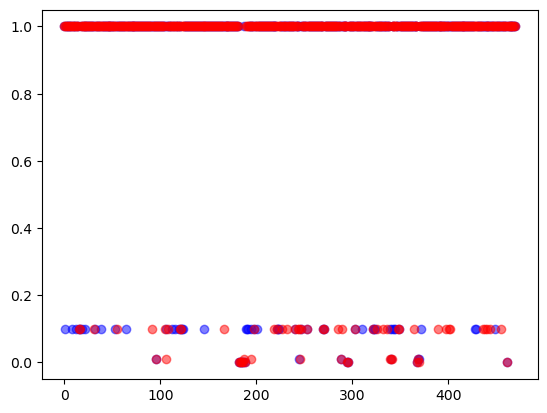

In [ ]:
plt.scatter(comparison.index, comparison["P-value_WT"], color="blue", label="WT", alpha=0.5)
plt.scatter(comparison.index, comparison["P-value_T419R"], color="red", label="T419R", alpha=0.5)

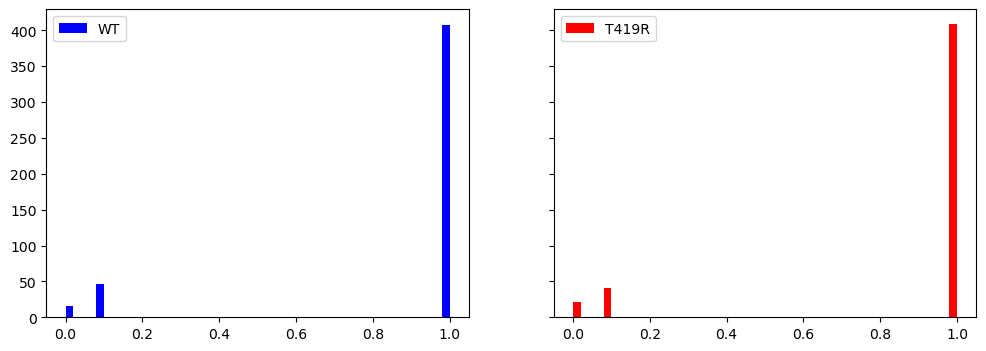

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
ax1, ax2 = axes.flatten()

ax1.hist(comparison["P-value_WT"], bins=50, color="blue", label="WT")
ax2.hist(comparison["P-value_T419R"], bins=50, color="red", label="T419R")

ax1.legend()
ax2.legend()

plt.show()

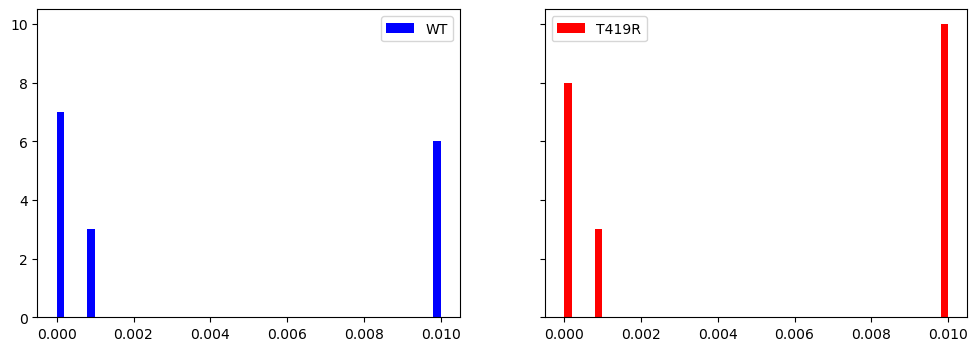

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
ax1, ax2 = axes.flatten()

ax1.hist(comparison[comparison["P-value_WT"] <0.05]["P-value_WT"], bins=50, color="blue", label="WT")
ax2.hist(comparison[comparison["P-value_T419R"] <0.05]["P-value_T419R"], bins=50, color="red", label="T419R")

ax1.legend()
ax2.legend()

plt.show()

The number of significant motifs is slightly higher for T419R than for WT.

**Comparison**

Motifs significant for T419R and not significant for WT.

In [20]:
comparison_uniqueT419R = comparison[(comparison["P-value_T419R"] < 0.05) & (comparison["P-value_WT"] > 0.05)]

In [21]:
comparison_uniqueT419R.shape

(6, 17)

In [22]:
comparison_uniqueT419R[["Motif Name", "P-value_WT", "P-value_T419R", "% of Target Sequences with Motif_WT", "% of Target Sequences with Motif_T419R", "Consensus_T419R", "q-value (Benjamini)_WT", "q-value (Benjamini)_T419R"]].sort_values(by="P-value_T419R", ascending=False)

,Motif Name,P-value_WT,P-value_T419R,% of Target Sequences with Motif_WT,% of Target Sequences with Motif_T419R,Consensus_T419R,q-value (Benjamini)_WT,q-value (Benjamini)_T419R
106,FOXK2(Forkhead)/U2OS-FOXK2-ChIP-Seq(E-MTAB-220...,0.1,0.01,15.22%,11.46%,SCHTGTTTACAT,0.7548,0.1803
187,IRF:BATF(IRF:bZIP)/pDC-Irf8-ChIP-Seq(GSE66899)...,1.0,0.01,2.17%,3.82%,CTTTCANTATGACTV,1.0000,0.1939
195,KLF14(Zf)/HEK293-KLF14.GFP-ChIP-Seq(GSE58341)/...,0.1,0.01,65.22%,68.15%,RGKGGGCGKGGC,0.4844,0.1803
246,NFkB-p65-Rel(RHD)/ThioMac-LPS-Expression(GSE23...,1.0,0.01,4.35%,3.82%,GGAAATTCCC,0.7713,0.1803
339,STAT1(Stat)/HelaS3-STAT1-ChIP-Seq(GSE12782)/Homer,0.1,0.01,13.04%,10.19%,NATTTCCNGGAAAT,0.5304,0.0500
341,STAT5(Stat)/mCD4+-Stat5-ChIP-Seq(GSE12346)/Homer,0.1,0.01,15.22%,9.55%,RTTTCTNAGAAA,0.3925,0.1803


Motifs significant WT and not significant for T419R.

In [23]:
comparison_uniqueWT = comparison[(comparison["P-value_T419R"] > 0.05) & (comparison["P-value_WT"] < 0.05)]

In [24]:
comparison_uniqueWT.shape

(1, 17)

In [25]:
comparison_uniqueWT[["Motif Name", "P-value_WT", "P-value_T419R", "% of Target Sequences with Motif_WT", "% of Target Sequences with Motif_T419R", "Consensus_T419R", "q-value (Benjamini)_WT", "q-value (Benjamini)_T419R"]]

,Motif Name,P-value_WT,P-value_T419R,% of Target Sequences with Motif_WT,% of Target Sequences with Motif_T419R,Consensus_T419R,q-value (Benjamini)_WT,q-value (Benjamini)_T419R
245,NFkB-p65(RHD)/GM12787-p65-ChIP-Seq(GSE19485)/H...,0.01,0.1,21.74%,12.10%,WGGGGATTTCCC,0.2545,0.6768


### Custom promoter region (-200, +50)

The original paper (Giovannozzi S, Demeulemeester J, Schrijvers R and Gijsbers R (2021) Transcriptional Profiling of STAT1 Gain-of-Function Reveals Common and Mutation-Specific Fingerprints. Front. Immunol. 12:632997. doi: 10.3389/fimmu.2021.632997) used a region of -200,+50 around the TSS for promoter analysis.

> "We therefore identified and analyzed the promoters of the genes up-regulated after IFNγ stimulation. A short promoter region [from −200 to +50 bp around the Transcription Start Site (TSS)] was retrieved for all up-regulated genes using the Eukaryotic Promoter Database (EPD) web tool."

The next section repeats the previous analysis with those promoter region parameters, which are more restrictive than the HOMER defaults.

In [ ]:
! findMotifs.pl up_WT.txt human up_WT_200_50/ -p 8 -start -200 -end 50


Selected Options:
	Input file = up_WT.txt
	Promoter Set = human
	Output Directory = up_WT_200_50/
	Using 8 CPUs
	New start is -200 relative to the TSS
	New end is 50 relative to the TSS
	Found mset for "human", will check against vertebrates motifs

	Progress: Step1 - Convert input file to refseq IDs
	Percentage of IDs converted into refseq: 90.4% (47 out of 52)

	Progress: Step2 - prepare sequence files

	Progress: Step3 - creating foreground/background file

	Progress: Step4 - removing redundant promoters
		Kept 47797 of 53293

	Progress: Step5 - adjusting background sequences for GC/CpG content...
	Bin	# Targets	# Background	Background Weight
	3	2	1374	1.462
	4	3	2297	1.312
	5	6	3224	1.870
	6	7	3887	1.809
	7	13	12945	1.009
	8	14	15302	0.919
	9	1	7182	0.140

	Normalizing lower order oligos using homer2

	Reading input files...
	46257 total sequences read
	Autonormalization: 1-mers (4 total)
		A	22.42%	22.51%	0.996
		C	27.58%	27.49%	1.003
		G	27.58%	27.49%	1.003
		T	22.42%	22.51%	0.9

In [ ]:
! findMotifs.pl up_T419R.txt human up_T419R_200_50/ -p 8 -start -200 -end 50


Selected Options:
	Input file = up_T419R.txt
	Promoter Set = human
	Output Directory = up_T419R_200_50/
	Using 8 CPUs
	New start is -200 relative to the TSS
	New end is 50 relative to the TSS
	Found mset for "human", will check against vertebrates motifs

	Progress: Step1 - Convert input file to refseq IDs
	Percentage of IDs converted into refseq: 90.6% (163 out of 180)

	Progress: Step2 - prepare sequence files

	Progress: Step3 - creating foreground/background file

	Progress: Step4 - removing redundant promoters
		Kept 47801 of 53297

	Progress: Step5 - adjusting background sequences for GC/CpG content...
	Bin	# Targets	# Background	Background Weight
	3	3	1373	0.642
	4	8	2292	1.025
	5	12	3218	1.095
	6	13	3881	0.984
	7	43	12915	0.978
	8	47	15269	0.904
	9	31	7152	1.273

	Normalizing lower order oligos using homer2

	Reading input files...
	46257 total sequences read
	Autonormalization: 1-mers (4 total)
		A	20.08%	19.95%	1.007
		C	29.92%	30.05%	0.996
		G	29.92%	30.05%	0.996
		T	20.08%

In [26]:
WT_motifs_200_50 = pd.read_csv("up_WT_200_50/knownResults.txt", sep="\t")
T419R_motifs_200_50 = pd.read_csv("up_T419R_200_50/knownResults.txt", sep="\t")

comparison_200_50 = pd.merge(WT_motifs_200_50.drop_duplicates(subset="Motif Name"), T419R_motifs_200_50.drop_duplicates(subset="Motif Name"), on="Motif Name", how="outer", suffixes=("_WT", "_T419R"))

Check for motifs present in only one of the dataframes.

In [27]:
comparison_200_50.isna().sum()

Motif Name                                        0
Consensus_WT                                      0
P-value_WT                                        0
Log P-value_WT                                    0
q-value (Benjamini)_WT                            0
# of Target Sequences with Motif(of 46)           0
% of Target Sequences with Motif_WT               0
# of Background Sequences with Motif(of 42368)    0
% of Background Sequences with Motif_WT           0
Consensus_T419R                                   0
P-value_T419R                                     0
Log P-value_T419R                                 0
q-value (Benjamini)_T419R                         0
# of Target Sequences with Motif(of 157)          0
% of Target Sequences with Motif_T419R            0
# of Background Sequences with Motif(of 45202)    0
% of Background Sequences with Motif_T419R        0
dtype: int64

In [28]:
comparison_200_50[(comparison_200_50["% of Target Sequences with Motif_WT"] == "0.00%") & (comparison_200_50["% of Target Sequences with Motif_T419R"] != "0.00%")].shape

(74, 17)

In [29]:
comparison_200_50[(comparison_200_50["% of Target Sequences with Motif_WT"] == "0.00%") & (comparison_200_50["% of Target Sequences with Motif_T419R"] != "0.00%")][["% of Target Sequences with Motif_T419R", "P-value_T419R"]].sort_values("P-value_T419R", ascending=True).head()

,% of Target Sequences with Motif_T419R,P-value_T419R
31,2.55%,0.01
219,3.18%,0.10
444,5.73%,0.10
441,3.18%,0.10
30,1.27%,1.00


In [30]:
comparison_200_50[(comparison_200_50["% of Target Sequences with Motif_WT"] != "0.00%") & (comparison_200_50["% of Target Sequences with Motif_T419R"] == "0.00%")].shape

(1, 17)

In [31]:
comparison_200_50[(comparison_200_50["% of Target Sequences with Motif_WT"] != "0.00%") & (comparison_200_50["% of Target Sequences with Motif_T419R"] == "0.00%")][["% of Target Sequences with Motif_T419R", "P-value_WT"]].head()

,% of Target Sequences with Motif_T419R,P-value_WT
263,0.00%,1.0


Like with the default promoter region size, the same motifs were found for both dataframes. There are several motifs that are present with a very low frequency in the WT upregulated gene promoters (< 0.01 \%), but only one of them is significant in the T419R set. Conversely, only one motif is present with such a low frequency in the T419R set, and it is not significant in the WT set.

**Comparison**

7 motifs are significant in T419R but not significant in WT.

In [32]:
comparison_200_50_uniqueT419R = comparison_200_50[(comparison_200_50["P-value_T419R"] < 0.05) & (comparison_200_50["P-value_WT"] > 0.05)]

In [33]:
comparison_200_50_uniqueT419R.shape

(7, 17)

In [34]:
comparison_200_50_uniqueT419R[["Motif Name", "P-value_WT", "P-value_T419R", "% of Target Sequences with Motif_WT", "% of Target Sequences with Motif_T419R", "Consensus_T419R", "q-value (Benjamini)_WT", "q-value (Benjamini)_T419R"]].sort_values("P-value_T419R", ascending=True).head(10)

,Motif Name,P-value_WT,P-value_T419R,% of Target Sequences with Motif_WT,% of Target Sequences with Motif_T419R,Consensus_T419R,q-value (Benjamini)_WT,q-value (Benjamini)_T419R
31,"Brn2(POU,Homeobox)/NPC-Brn2-ChIP-Seq(GSE35496)...",1.0,0.01,0.00%,2.55%,ATGAATATTC,1.0000,0.0578
106,FOXK2(Forkhead)/U2OS-FOXK2-ChIP-Seq(E-MTAB-220...,1.0,0.01,10.87%,10.19%,SCHTGTTTACAT,0.8599,0.0514
108,FOXP1(Forkhead)/H9-FOXP1-ChIP-Seq(GSE31006)/Homer,0.1,0.01,8.70%,6.37%,NYYTGTTTACHN,0.8450,0.2411
122,Foxo3(Forkhead)/U2OS-Foxo3-ChIP-Seq(E-MTAB-270...,0.1,0.01,15.22%,8.92%,DGTAAACA,0.3787,0.2411
246,NFkB-p65-Rel(RHD)/ThioMac-LPS-Expression(GSE23...,0.1,0.01,4.35%,3.82%,GGAAATTCCC,0.8599,0.0794
339,STAT1(Stat)/HelaS3-STAT1-ChIP-Seq(GSE12782)/Homer,0.1,0.01,10.87%,8.28%,NATTTCCNGGAAAT,0.6270,0.0763
389,Tbx20(T-box)/Heart-Tbx20-ChIP-Seq(GSE29636)/Homer,1.0,0.01,2.17%,4.46%,GGTGYTGACAGS,1.0000,0.2411


3 motifs are significant in WT but not significant in T419R.

In [35]:
comparison_200_50_uniqueWT = comparison_200_50[(comparison_200_50["P-value_T419R"] > 0.05) & (comparison_200_50["P-value_WT"] < 0.05)]

In [36]:
comparison_200_50_uniqueWT.shape

(3, 17)

In [37]:
comparison_200_50_uniqueWT[["Motif Name", "P-value_WT", "P-value_T419R", "% of Target Sequences with Motif_WT", "% of Target Sequences with Motif_T419R", "Consensus_T419R", "q-value (Benjamini)_WT", "q-value (Benjamini)_T419R"]].head(10)

,Motif Name,P-value_WT,P-value_T419R,% of Target Sequences with Motif_WT,% of Target Sequences with Motif_T419R,Consensus_T419R,q-value (Benjamini)_WT,q-value (Benjamini)_T419R
245,NFkB-p65(RHD)/GM12787-p65-ChIP-Seq(GSE19485)/H...,0.010,0.1,17.39%,10.19%,WGGGGATTTCCC,0.2922,0.4313
368,Stat3(Stat)/mES-Stat3-ChIP-Seq(GSE11431)/Homer,0.001,0.1,26.09%,14.01%,CTTCCGGGAA,0.0193,0.2962
369,Stat3+il21(Stat)/CD4-Stat3-ChIP-Seq(GSE19198)/...,0.010,0.1,26.09%,14.01%,SVYTTCCNGGAARB,0.0423,0.3692


### WT as background (-200, +50)

In [ ]:
! findMotifs.pl up_T419R.txt human up_T419R_200_50_bg/ -p 14 -start -200 -end 50 -bg up_WT.txt


Selected Options:
	Input file = up_T419R.txt
	Promoter Set = human
	Output Directory = up_T419R_200_50_bg/
	Using 14 CPUs
	New start is -200 relative to the TSS
	New end is 50 relative to the TSS
	background file: up_WT.txt
	Found mset for "human", will check against vertebrates motifs

	Progress: Step1 - Convert input file to refseq IDs
	Percentage of IDs converted into refseq: 90.6% (163 out of 180)

	Progress: Step2 - prepare sequence files

	Progress: Step3 - creating foreground/background file

	Progress: Step4 - removing redundant promoters
		Kept 169 of 169

	Progress: Step5 - adjusting background sequences for GC/CpG content...
	Bin	# Targets	# Background	Background Weight
	5	12	1	0.626
	6	13	2	0.339
	7	43	1	2.243
	8	47	2	1.226

	Normalizing lower order oligos using homer2

	Reading input files...
	121 total sequences read
	Autonormalization: 1-mers (4 total)
		A	20.92%	19.69%	1.062
		C	29.08%	30.31%	0.960
		G	29.08%	30.31%	0.960
		T	20.92%	19.69%	1.062
	Autonormalization: 2-m

This results in all non-significant de novo motifs and no known motifs identified.

### T419R - WT (-200, +50)

In [ ]:
unique_T419R = list(set(df_up['T419R']) - set(df_up['WT']))

In [ ]:
len(unique_T419R)

134

In [ ]:
with open('up_T419R_unique.txt', 'w') as f:
    for item in unique_T419R:
        f.write(f"{item}\n")

In [ ]:
! findMotifs.pl up_T419R_unique.txt human up_T419R_unique_200_50/ -p 14 -start -200 -end 50


Selected Options:
	Input file = up_T419R_unique.txt
	Promoter Set = human
	Output Directory = up_T419R_unique_200_50/
	Using 14 CPUs
	New start is -200 relative to the TSS
	New end is 50 relative to the TSS
	Found mset for "human", will check against vertebrates motifs

	Progress: Step1 - Convert input file to refseq IDs
	Percentage of IDs converted into refseq: 91.0% (122 out of 134)

	Progress: Step2 - prepare sequence files

	Progress: Step3 - creating foreground/background file

	Progress: Step4 - removing redundant promoters
		Kept 47801 of 53297

	Progress: Step5 - adjusting background sequences for GC/CpG content...
	Bin	# Targets	# Background	Background Weight
	3	1	1375	0.287
	4	5	2295	0.859
	5	7	3223	0.857
	6	8	3886	0.812
	7	31	12927	0.946
	8	35	15281	0.903
	9	30	7153	1.654

	Normalizing lower order oligos using homer2

	Reading input files...
	46257 total sequences read
	Autonormalization: 1-mers (4 total)
		A	19.24%	19.08%	1.009
		C	30.76%	30.92%	0.995
		G	30.76%	30.92%	0.9

This results in the identification of a 12 significant known motifs, compared to the 20 identified for up_T419R_200_50/ (full upregulated gene list, default background). 

In [ ]:
! findMotifs.pl up_T419R_unique.txt human up_T419R_unique_200_50_bgT419R/ -p 14 -start -200 -end 50 -bg up_T419R.txt


Selected Options:
	Input file = up_T419R_unique.txt
	Promoter Set = human
	Output Directory = up_T419R_unique_200_50_bgT419R/
	Using 14 CPUs
	New start is -200 relative to the TSS
	New end is 50 relative to the TSS
	background file: up_T419R.txt
	Found mset for "human", will check against vertebrates motifs

	Progress: Step1 - Convert input file to refseq IDs
	Percentage of IDs converted into refseq: 91.0% (122 out of 134)

	Progress: Step2 - prepare sequence files

	Progress: Step3 - creating foreground/background file

	Progress: Step4 - removing redundant promoters
		Kept 163 of 163

	Progress: Step5 - adjusting background sequences for GC/CpG content...
	Bin	# Targets	# Background	Background Weight
	3	1	2	0.171
	4	5	3	0.570
	5	7	5	0.479
	6	8	5	0.547
	7	31	12	0.883
	8	35	12	0.997
	9	30	1	10.256

	Normalizing lower order oligos using homer2

	Reading input files...
	157 total sequences read
	Autonormalization: 1-mers (4 total)
		A	19.24%	19.04%	1.010
		C	30.76%	30.96%	0.994
		G	30.7

This results in the identification of a single significant known motif.

## Other mutations: R274W, R321S, E411A, N574I

Extract upregulated gene lists.

In [38]:
up_cols = df_up.columns
up_cols 

Index(['WT', 'R274W', 'R321S', 'E411A', 'T419R', 'N574I'], dtype='object')

In [39]:
for col in up_cols :
    df_up[col].dropna().to_csv(f'up_{col}.txt', index=False)

Find motifs with the default promoter region (-300, +50).

In [ ]:
for col in ['R274W', 'R321S', 'E411A', 'N574I']:
    cmd = f"findMotifs.pl up_{col}.txt human up_{col}/ -p 14 &> log/log_findMotifs_{col}.log"
    !{cmd}

^C


In [ ]:
for col in ['R274W', 'R321S', 'E411A', 'N574I']:
    cmd = f"findMotifs.pl up_{col}.txt human up_{col}_200_50/ -p 14 -start -200 -end 50 &> log/log_findMotifs_{col}_200_50.log"
    !{cmd}

### Known motifs

In [40]:
motif_dfs = {}

for col in up_cols:
    key_motifs = f"{col}_motifs"
    key_motifs_200_50 = f"{col}_motifs_200_50"

    print(key_motifs)
    motif_dfs[key_motifs] = pd.read_csv(f"up_{col}/knownResults.txt", sep="\t")
    print(motif_dfs[key_motifs].shape)
    
    print(key_motifs_200_50)
    motif_dfs[key_motifs_200_50] = pd.read_csv(f"up_{col}_200_50/knownResults.txt", sep="\t")
    print(motif_dfs[key_motifs_200_50].shape)


WT_motifs
(472, 9)
WT_motifs_200_50
(472, 9)
R274W_motifs
(472, 9)
R274W_motifs_200_50
(472, 9)
R321S_motifs
(472, 9)
R321S_motifs_200_50
(472, 9)
E411A_motifs
(472, 9)
E411A_motifs_200_50
(472, 9)
T419R_motifs
(472, 9)
T419R_motifs_200_50
(472, 9)
N574I_motifs
(472, 9)
N574I_motifs_200_50
(472, 9)


In [41]:
motif_dfs.keys()

dict_keys(['WT_motifs', 'WT_motifs_200_50', 'R274W_motifs', 'R274W_motifs_200_50', 'R321S_motifs', 'R321S_motifs_200_50', 'E411A_motifs', 'E411A_motifs_200_50', 'T419R_motifs', 'T419R_motifs_200_50', 'N574I_motifs', 'N574I_motifs_200_50'])

In [42]:
motif_keys = list(motif_dfs.keys())  # Convert dict_keys to a list
comparison = motif_dfs[motif_keys[0]].drop_duplicates(subset="Motif Name").copy()
comparison.name = motif_keys[0].replace('_motifs', '')

# Merge with the rest
for key in motif_keys[1:]:
    right_df = motif_dfs[key].drop_duplicates(subset="Motif Name")
    right_df.name = key.replace('_motifs', '')
    comparison = pd.merge(
        comparison,
        right_df,
        on="Motif Name",
        how="outer",
        suffixes=(f"_{comparison.name}", f"_{right_df.name}")
    )
    comparison.name = right_df.name  # Update name for next iteration

In [43]:
comparison.columns

Index(['Motif Name', 'Consensus_WT', 'P-value_WT', 'Log P-value_WT',
       'q-value (Benjamini)_WT', '# of Target Sequences with Motif(of 46)_WT',
       '% of Target Sequences with Motif_WT',
       '# of Background Sequences with Motif(of 43551)',
       '% of Background Sequences with Motif_WT', 'Consensus_WT_200_50',
       'P-value_WT_200_50', 'Log P-value_WT_200_50',
       'q-value (Benjamini)_WT_200_50',
       '# of Target Sequences with Motif(of 46)_WT_200_50',
       '% of Target Sequences with Motif_WT_200_50',
       '# of Background Sequences with Motif(of 42368)',
       '% of Background Sequences with Motif_WT_200_50', 'Consensus_R274W',
       'P-value_R274W', 'Log P-value_R274W', 'q-value (Benjamini)_R274W',
       '# of Target Sequences with Motif(of 121)_R274W',
       '% of Target Sequences with Motif_R274W',
       '# of Background Sequences with Motif(of 45218)',
       '% of Background Sequences with Motif_R274W', 'Consensus_R274W_200_50',
       'P-value_R274W

In [44]:
# Assuming 'comparison' is the merged DataFrame from your previous step
# Select columns: 'Motif Name' and all 'P-value_{mutation}' columns
pvalue_cols = [col for col in comparison.columns if col.startswith('P-value_')]

# Create a DataFrame with only the relevant columns
df_pvalues = comparison[['Motif Name'] + pvalue_cols].copy()

In [45]:
df_pvalues.head()

,Motif Name,P-value_WT,P-value_WT_200_50,P-value_R274W,P-value_R274W_200_50,P-value_R321S,P-value_R321S_200_50,P-value_E411A,P-value_E411A_200_50,P-value_T419R,P-value_T419R_200_50,P-value_N574I,P-value_N574I_200_50
0,AMYB(HTH)/Testes-AMYB-ChIP-Seq(GSE44588)/Homer,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.00,1.0,1.0,1.0,1.0
1,AP-1(bZIP)/ThioMac-PU.1-ChIP-Seq(GSE21512)/Homer,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.01,1.0,1.0,0.1,0.1
2,AP-2alpha(AP2)/Hela-AP2alpha-ChIP-Seq(GSE31477...,1.0,1.0,0.1,1.0,1.0,1.0,1.0,1.00,1.0,1.0,1.0,1.0
3,AP-2gamma(AP2)/MCF7-TFAP2C-ChIP-Seq(GSE21234)/...,1.0,1.0,0.1,1.0,1.0,1.0,1.0,1.00,1.0,1.0,1.0,1.0
4,AR-halfsite(NR)/LNCaP-AR-ChIP-Seq(GSE27824)/Homer,1.0,0.1,1.0,1.0,1.0,1.0,1.0,1.00,1.0,1.0,1.0,1.0


In [46]:
# Filter for rows where any P-value column is less than or equal to 0.05
df_pvalues_filtered = df_pvalues[df_pvalues[pvalue_cols].astype(float).le(0.05).any(axis=1)]
df_pvalues_filtered.head()

,Motif Name,P-value_WT,P-value_WT_200_50,P-value_R274W,P-value_R274W_200_50,P-value_R321S,P-value_R321S_200_50,P-value_E411A,P-value_E411A_200_50,P-value_T419R,P-value_T419R_200_50,P-value_N574I,P-value_N574I_200_50
1,AP-1(bZIP)/ThioMac-PU.1-ChIP-Seq(GSE21512)/Homer,0.1,0.1,0.10,0.10,0.10,0.10,0.10,0.01,1.0,1.00,0.1,0.10
18,BATF(bZIP)/Th17-BATF-ChIP-Seq(GSE39756)/Homer,0.1,0.1,1.00,1.00,0.10,0.10,0.01,0.01,1.0,1.00,0.1,0.10
31,"Brn2(POU,Homeobox)/NPC-Brn2-ChIP-Seq(GSE35496)...",1.0,1.0,1.00,1.00,1.00,1.00,1.00,1.00,0.1,0.01,1.0,1.00
53,DMRT1(DM)/Testis-DMRT1-ChIP-Seq(GSE64892)/Homer,0.1,0.1,1.00,1.00,1.00,0.10,0.01,0.01,1.0,0.10,0.1,0.01
55,DUX(Homeobox)/C2C12-Dux-ChIP-Seq(GSE87279)/Homer,1.0,1.0,0.01,0.01,0.01,0.01,1.00,1.00,0.1,1.00,0.1,1.00


In [47]:
# Pivot the DataFrame to have 'Motif Name' as index and mutations as columns
# Extract mutation names from column names (e.g., 'P-value_WT' -> 'WT')
df_pvalues_filtered.columns = ['Motif Name'] + [col.replace('P-value_', '') for col in df_pvalues.columns if col.startswith('P-value_')]
df_pivot = df_pvalues_filtered.set_index('Motif Name')
df_pivot.head()

,WT,WT_200_50,R274W,R274W_200_50,R321S,R321S_200_50,E411A,E411A_200_50,T419R,T419R_200_50,N574I,N574I_200_50
Motif Name,,,,,,,,,,,,
AP-1(bZIP)/ThioMac-PU.1-ChIP-Seq(GSE21512)/Homer,0.1,0.1,0.10,0.10,0.10,0.10,0.10,0.01,1.0,1.00,0.1,0.10
BATF(bZIP)/Th17-BATF-ChIP-Seq(GSE39756)/Homer,0.1,0.1,1.00,1.00,0.10,0.10,0.01,0.01,1.0,1.00,0.1,0.10
"Brn2(POU,Homeobox)/NPC-Brn2-ChIP-Seq(GSE35496)/Homer",1.0,1.0,1.00,1.00,1.00,1.00,1.00,1.00,0.1,0.01,1.0,1.00
DMRT1(DM)/Testis-DMRT1-ChIP-Seq(GSE64892)/Homer,0.1,0.1,1.00,1.00,1.00,0.10,0.01,0.01,1.0,0.10,0.1,0.01
DUX(Homeobox)/C2C12-Dux-ChIP-Seq(GSE87279)/Homer,1.0,1.0,0.01,0.01,0.01,0.01,1.00,1.00,0.1,1.00,0.1,1.00


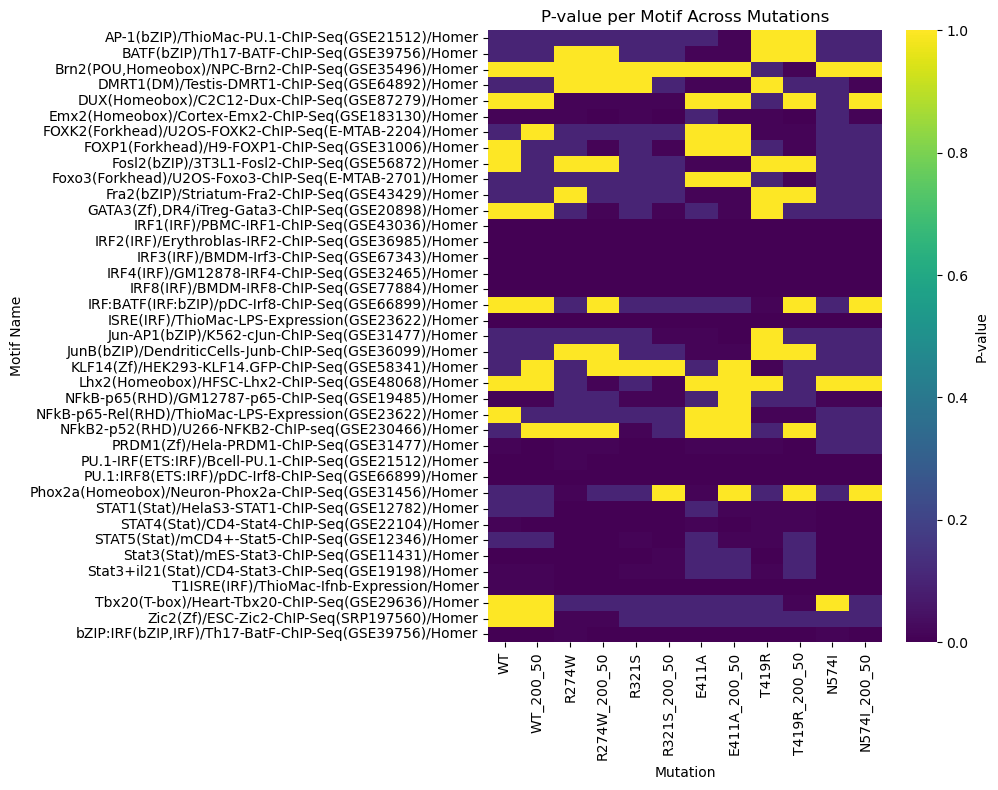

In [48]:
plt.figure(figsize=(10, 8))
sns.heatmap(df_pivot, cmap='viridis', cbar_kws={'label': 'P-value'})
plt.title('P-value per Motif Across Mutations')
plt.xlabel('Mutation')
plt.ylabel('Motif Name')
plt.tight_layout()
plt.show()

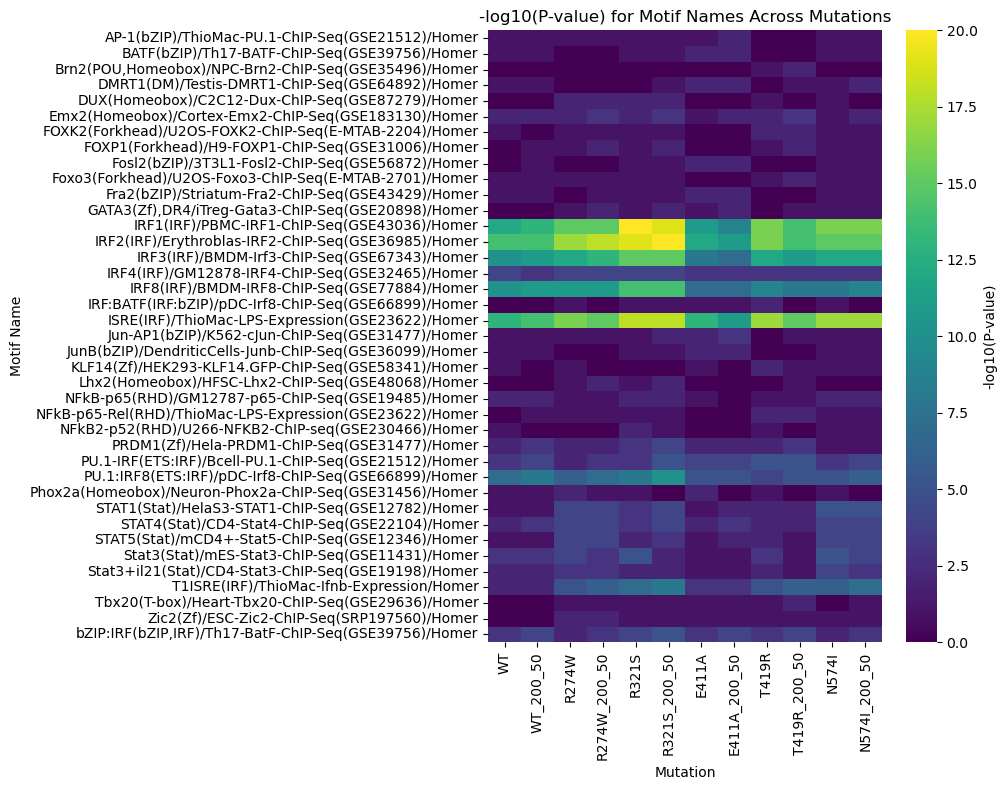

In [49]:
df_pivot_log10 = -np.log10(df_pivot)

plt.figure(figsize=(10, 8))
sns.heatmap(df_pivot_log10, cmap='viridis', cbar_kws={'label': '-log10(P-value)'})
plt.title('-log10(P-value) for Motif Names Across Mutations')
plt.xlabel('Mutation')
plt.ylabel('Motif Name')
plt.tight_layout()
plt.show()

In [50]:
df_pivot.columns

Index(['WT', 'WT_200_50', 'R274W', 'R274W_200_50', 'R321S', 'R321S_200_50',
       'E411A', 'E411A_200_50', 'T419R', 'T419R_200_50', 'N574I',
       'N574I_200_50'],
      dtype='object')

In [51]:
df_pivot_bool = df_pivot.copy()
df_pivot_bool[df_pivot.columns] = np.where(df_pivot[df_pivot.columns] < 0.05, 1, 0)
df_pivot_bool.head()

,WT,WT_200_50,R274W,R274W_200_50,R321S,R321S_200_50,E411A,E411A_200_50,T419R,T419R_200_50,N574I,N574I_200_50
Motif Name,,,,,,,,,,,,
AP-1(bZIP)/ThioMac-PU.1-ChIP-Seq(GSE21512)/Homer,0,0,0,0,0,0,0,1,0,0,0,0
BATF(bZIP)/Th17-BATF-ChIP-Seq(GSE39756)/Homer,0,0,0,0,0,0,1,1,0,0,0,0
"Brn2(POU,Homeobox)/NPC-Brn2-ChIP-Seq(GSE35496)/Homer",0,0,0,0,0,0,0,0,0,1,0,0
DMRT1(DM)/Testis-DMRT1-ChIP-Seq(GSE64892)/Homer,0,0,0,0,0,0,1,1,0,0,0,1
DUX(Homeobox)/C2C12-Dux-ChIP-Seq(GSE87279)/Homer,0,0,1,1,1,1,0,0,0,0,0,0


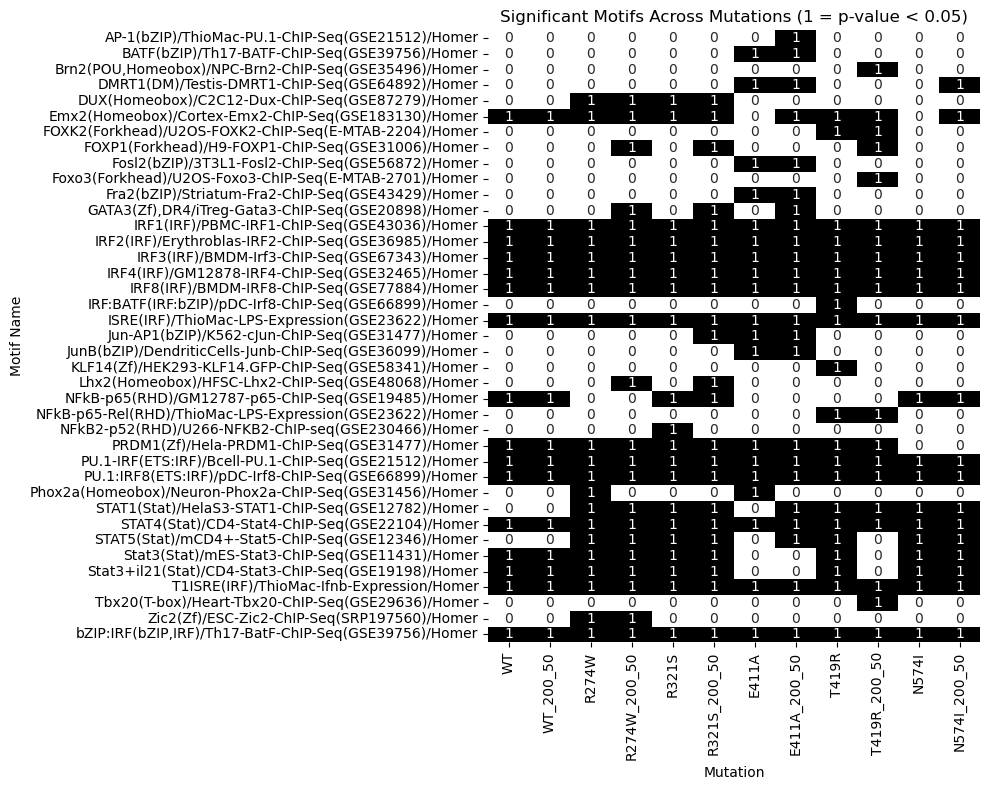

In [52]:
plt.figure(figsize=(10, 8))
sns.heatmap(df_pivot_bool, annot=True, cmap='binary', cbar=False)
plt.title('Significant Motifs Across Mutations (1 = p-value < 0.05)')
plt.xlabel('Mutation')
plt.ylabel('Motif Name')
plt.tight_layout()
plt.show()

Filter out motifs that are significant in all mutations.

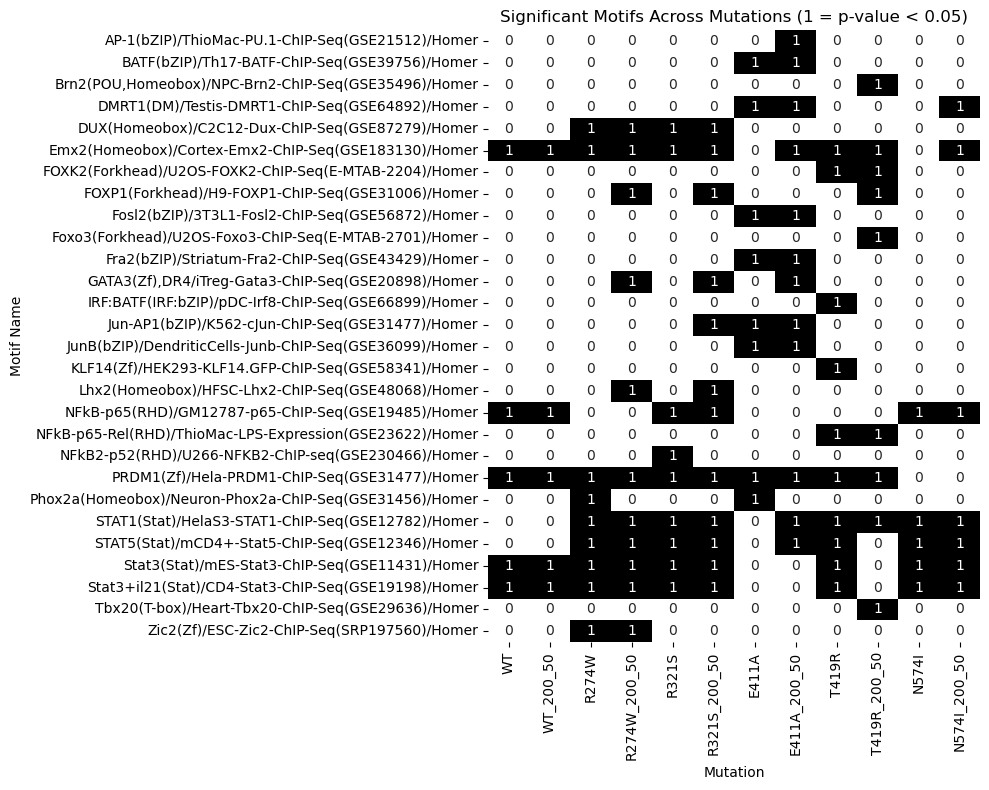

In [53]:
df_pivot_filtered = df_pivot[df_pivot[df_pivot.columns].gt(0.05).any(axis=1)]
df_pivot_bool_filtered = df_pivot_filtered.copy()
df_pivot_bool_filtered[df_pivot.columns] = np.where(df_pivot_filtered[df_pivot.columns] < 0.05, 1, 0)

plt.figure(figsize=(10, 8))
sns.heatmap(df_pivot_bool_filtered, annot=True, cmap='binary', cbar=False)
plt.title('Significant Motifs Across Mutations (1 = p-value < 0.05)')
plt.xlabel('Mutation')
plt.ylabel('Motif Name')
plt.tight_layout()
plt.show()

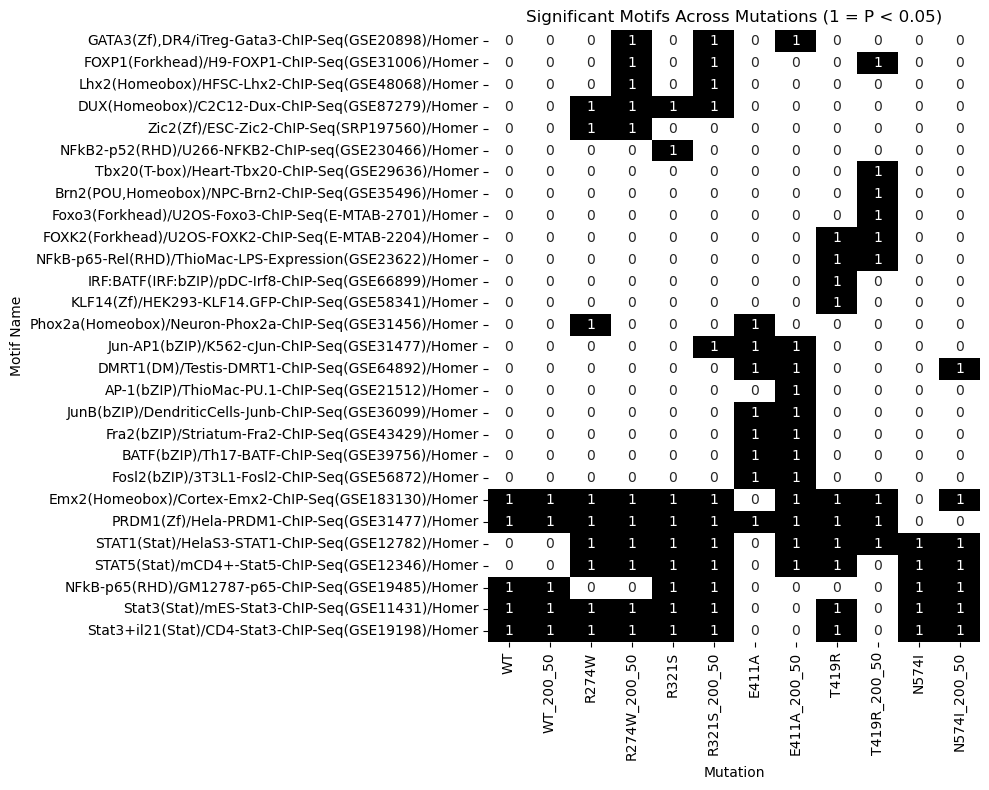

In [54]:
linkage = hierarchy.linkage(df_pivot_bool_filtered, method='average', metric='euclidean')

row_order = hierarchy.leaves_list(linkage)

df_pivot_bool_reordered = df_pivot_bool_filtered.iloc[row_order]

# Plot the heatmap with reordered rows
plt.figure(figsize=(10, 8))
sns.heatmap(df_pivot_bool_reordered,  annot=True, cmap='binary', cbar=False)
plt.title('Significant Motifs Across Mutations (1 = P < 0.05)')
plt.xlabel('Mutation')
plt.ylabel('Motif Name')
plt.tight_layout()
plt.show()

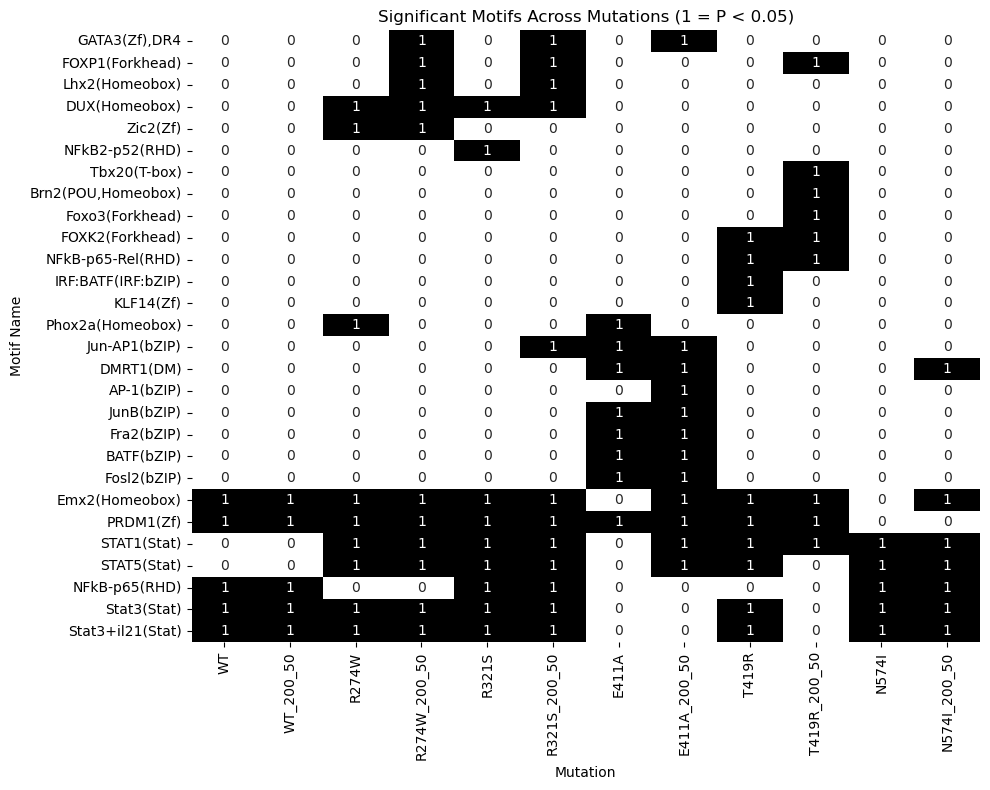

In [55]:
linkage = hierarchy.linkage(df_pivot_bool_filtered, method='average', metric='euclidean')

row_order = hierarchy.leaves_list(linkage)

df_pivot_bool_reordered = df_pivot_bool_filtered.iloc[row_order]
df_pivot_bool_reordered.index = df_pivot_bool_reordered.index.map(lambda x: x.split("/",1)[0])

# Plot the heatmap with reordered rows
plt.figure(figsize=(10, 8))
sns.heatmap(df_pivot_bool_reordered,  annot=True, cmap='binary', cbar=False)
plt.title('Significant Motifs Across Mutations (1 = P < 0.05)')
plt.xlabel('Mutation')
plt.ylabel('Motif Name')
plt.tight_layout()
plt.show()

Applying hierarchical clustering order to both rows (as in the previous plot) and columns, and displaying the dendrogram.

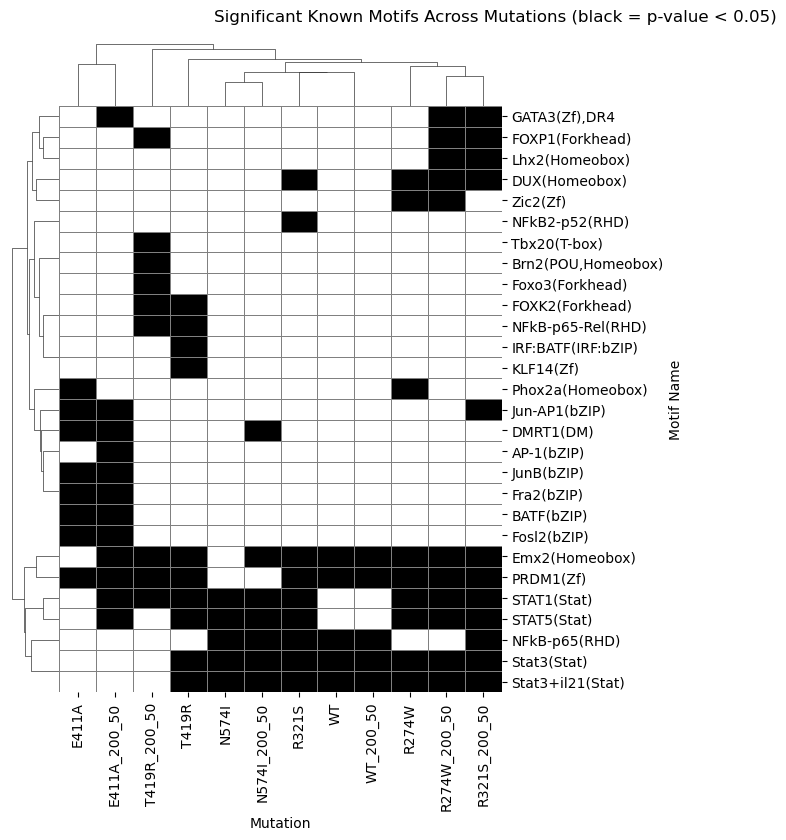

In [56]:
g = sns.clustermap(
    df_pivot_bool_filtered,
    method='average',
    metric='euclidean',
    cmap='binary',
    annot=False,
    cbar=False,
    lw=0.5,
    linecolor='grey',
    cbar_pos=None,
    dendrogram_ratio=0.1,
    figsize=(10, 8)
)

# Update motif names in the index
g.ax_heatmap.set_yticklabels([label.get_text().split("/", 1)[0] for label in g.ax_heatmap.get_yticklabels()])
g.figure.suptitle('Significant Known Motifs Across Mutations (black = p-value < 0.05)', y=1.02)  # Adjust y for positioning
g.ax_heatmap.set_xlabel('Mutation')
g.ax_heatmap.set_ylabel('Motif Name')

plt.show()

#### Filter by q-value

In [57]:
# Select columns: 'Motif Name' and all 'q-value' columns
qvalue_cols = [col for col in comparison.columns if col.startswith('q-value')]

df_qvalues = comparison[['Motif Name'] + qvalue_cols].copy()

In [58]:
df_qvalues

,Motif Name,q-value (Benjamini)_WT,q-value (Benjamini)_WT_200_50,q-value (Benjamini)_R274W,q-value (Benjamini)_R274W_200_50,q-value (Benjamini)_R321S,q-value (Benjamini)_R321S_200_50,q-value (Benjamini)_E411A,q-value (Benjamini)_E411A_200_50,q-value (Benjamini)_T419R,q-value (Benjamini)_T419R_200_50,q-value (Benjamini)_N574I,q-value (Benjamini)_N574I_200_50
0,AMYB(HTH)/Testes-AMYB-ChIP-Seq(GSE44588)/Homer,1.0000,1.0000,1.0000,1.0000,1.0000,0.9415,1.0000,1.0000,1.0,1.0000,1.0000,0.9732
1,AP-1(bZIP)/ThioMac-PU.1-ChIP-Seq(GSE21512)/Homer,0.3925,0.4693,0.6773,0.5401,0.4635,0.3792,0.2446,0.1271,1.0,0.8173,0.5901,0.5687
2,AP-2alpha(AP2)/Hela-AP2alpha-ChIP-Seq(GSE31477...,0.7713,0.8599,0.5328,0.7685,0.8070,0.9125,1.0000,1.0000,1.0,1.0000,0.8550,0.9434
3,AP-2gamma(AP2)/MCF7-TFAP2C-ChIP-Seq(GSE21234)/...,0.9068,0.9215,0.6217,0.7627,0.8426,0.9125,1.0000,0.9592,1.0,0.9770,0.8636,0.9546
4,AR-halfsite(NR)/LNCaP-AR-ChIP-Seq(GSE27824)/Homer,0.8957,0.7216,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0,0.8641,1.0000,0.9434
...,...,...,...,...,...,...,...,...,...,...,...,...,...
466,p53(p53)/Saos-p53-ChIP-Seq(GSE15780)/Homer,1.0000,1.0000,0.8394,0.7224,0.8437,0.7689,1.0000,1.0000,1.0,0.8403,0.8550,0.8386
467,p53(p53)/Saos-p53-ChIP-Seq/Homer,1.0000,1.0000,0.8394,0.7224,0.8437,0.7689,1.0000,1.0000,1.0,0.8403,0.8550,0.8386
468,p53(p53)/mES-cMyc-ChIP-Seq(GSE11431)/Homer,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0,0.8149,1.0000,1.0000
469,p63(p53)/Keratinocyte-p63-ChIP-Seq(GSE17611)/H...,0.9068,1.0000,0.8568,0.9011,0.8691,0.9130,1.0000,1.0000,1.0,1.0000,0.8550,0.9434


In [59]:
# Filter for rows where any q-value column is less than or equal to 0.1
df_qvalues_filtered = df_qvalues[df_qvalues[qvalue_cols].astype(float).le(0.1).any(axis=1)]
df_qvalues_filtered.shape

(25, 13)

In [60]:
df_qvalues_filtered.columns = ['Motif Name'] + [col.replace('q-value (Benjamini)_', '') for col in df_qvalues.columns if col.startswith('q-value (Benjamini)_')]
df_qvalues_pivot = df_qvalues_filtered.set_index('Motif Name')
df_qvalues_pivot.head()

,WT,WT_200_50,R274W,R274W_200_50,R321S,R321S_200_50,E411A,E411A_200_50,T419R,T419R_200_50,N574I,N574I_200_50
Motif Name,,,,,,,,,,,,
"Brn2(POU,Homeobox)/NPC-Brn2-ChIP-Seq(GSE35496)/Homer",1.0000,1.0000,0.8071,0.8672,0.8316,0.9125,1.0000,1.0000,0.3240,0.0578,0.8550,0.9434
Emx2(Homeobox)/Cortex-Emx2-ChIP-Seq(GSE183130)/Homer,0.2805,0.0446,0.1132,0.0104,0.2113,0.0058,0.6252,0.1511,0.1794,0.0130,0.4241,0.1915
FOXK2(Forkhead)/U2OS-FOXK2-ChIP-Seq(E-MTAB-2204)/Homer,0.7548,0.8599,0.5328,0.3546,0.6253,0.4739,1.0000,1.0000,0.1803,0.0514,0.5973,0.5576
FOXP1(Forkhead)/H9-FOXP1-ChIP-Seq(GSE31006)/Homer,0.8438,0.8450,0.4455,0.0689,0.5239,0.1267,1.0000,1.0000,0.6645,0.2411,0.6024,0.3453
Fosl2(bZIP)/3T3L1-Fosl2-ChIP-Seq(GSE56872)/Homer,0.7713,0.8302,0.8568,0.6858,0.5770,0.4170,0.1453,0.0697,1.0000,0.8641,0.6042,0.5576


In [61]:
df_qvalues_pivot_bool = df_qvalues_pivot.copy()
df_qvalues_pivot_bool[df_qvalues_pivot.columns] = np.where(df_qvalues_pivot[df_qvalues_pivot.columns] < 0.1, 1, 0)
df_qvalues_pivot_bool.head()

,WT,WT_200_50,R274W,R274W_200_50,R321S,R321S_200_50,E411A,E411A_200_50,T419R,T419R_200_50,N574I,N574I_200_50
Motif Name,,,,,,,,,,,,
"Brn2(POU,Homeobox)/NPC-Brn2-ChIP-Seq(GSE35496)/Homer",0,0,0,0,0,0,0,0,0,1,0,0
Emx2(Homeobox)/Cortex-Emx2-ChIP-Seq(GSE183130)/Homer,0,1,0,1,0,1,0,0,0,1,0,0
FOXK2(Forkhead)/U2OS-FOXK2-ChIP-Seq(E-MTAB-2204)/Homer,0,0,0,0,0,0,0,0,0,1,0,0
FOXP1(Forkhead)/H9-FOXP1-ChIP-Seq(GSE31006)/Homer,0,0,0,1,0,0,0,0,0,0,0,0
Fosl2(bZIP)/3T3L1-Fosl2-ChIP-Seq(GSE56872)/Homer,0,0,0,0,0,0,0,1,0,0,0,0


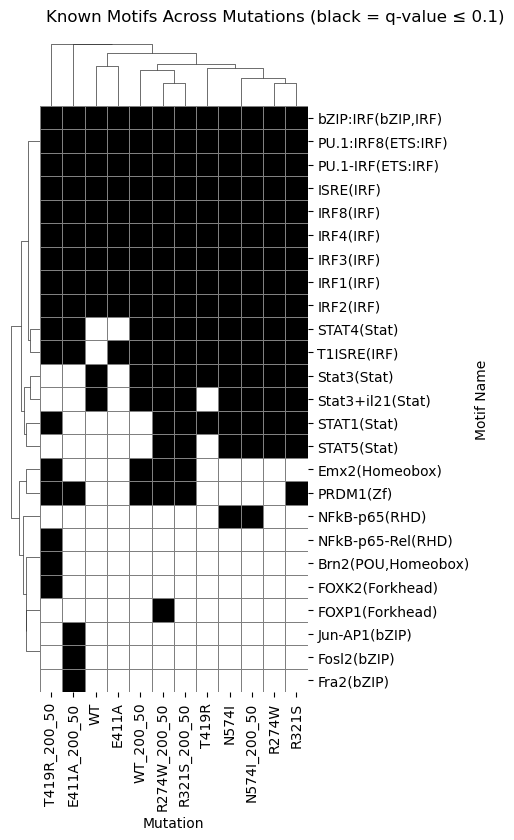

In [73]:
g = sns.clustermap(
    data = df_qvalues_pivot_bool,
    method='average',
    metric='euclidean',
    cmap='binary',
    lw=0.5,
    linecolor="gray",
    annot=False,
    cbar=False,
    cbar_pos=None,
    dendrogram_ratio=0.1,
    figsize=(8, 8)
)

# Update motif names in the index
g.ax_heatmap.set_yticklabels([label.get_text().split("/", 1)[0] for label in g.ax_heatmap.get_yticklabels()])
g.figure.suptitle('Known Motifs Across Mutations (black = q-value ≤ 0.1)', y=1.02, x=0.35) 
g.ax_heatmap.set_xlabel('Mutation')
g.ax_heatmap.set_ylabel('Motif Name')

plt.show()

In [67]:
# Filter rows where at least one column has a value of 0
dif_motifs = df_qvalues_pivot_bool[~df_qvalues_pivot_bool.eq(1).all(axis=1)]

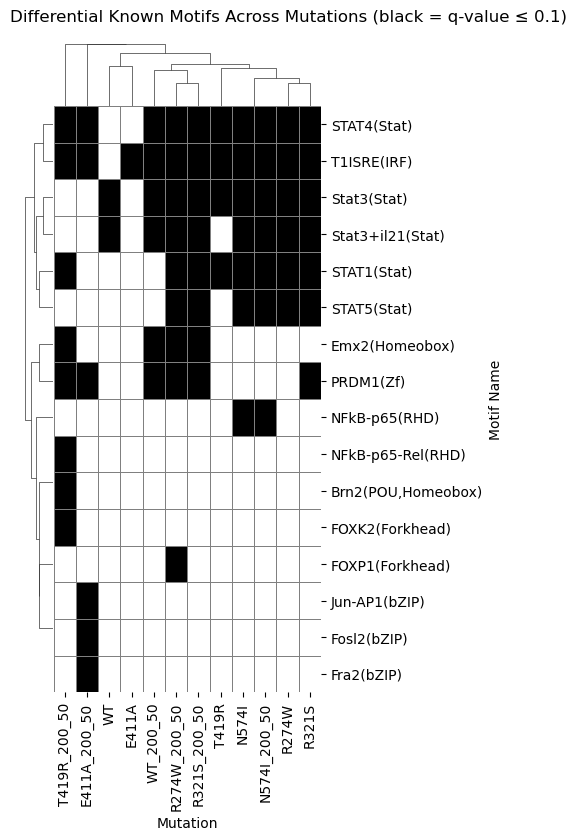

In [74]:
g = sns.clustermap(
    data = dif_motifs,
    method='average',
    metric='euclidean',
    cmap='binary',
    lw=0.5,
    linecolor="gray",
    annot=False,
    cbar=False,
    cbar_pos=None,
    dendrogram_ratio=0.1,
    figsize=(8, 8)
)

# Update motif names in the index
g.ax_heatmap.set_yticklabels([label.get_text().split("/", 1)[0] for label in g.ax_heatmap.get_yticklabels()])
g.figure.suptitle('Differential Known Motifs Across Mutations (black = q-value ≤ 0.1)', y=1.02, x=0.35) 
g.ax_heatmap.set_xlabel('Mutation')
g.ax_heatmap.set_ylabel('Motif Name')

plt.show()

#### Target gene %

In [742]:
comparison.columns

Index(['Motif Name', 'Consensus_WT', 'P-value_WT', 'Log P-value_WT',
       'q-value (Benjamini)_WT', '# of Target Sequences with Motif(of 46)_WT',
       '% of Target Sequences with Motif_WT',
       '# of Background Sequences with Motif(of 43551)',
       '% of Background Sequences with Motif_WT', 'Consensus_WT_200_50',
       'P-value_WT_200_50', 'Log P-value_WT_200_50',
       'q-value (Benjamini)_WT_200_50',
       '# of Target Sequences with Motif(of 46)_WT_200_50',
       '% of Target Sequences with Motif_WT_200_50',
       '# of Background Sequences with Motif(of 42368)',
       '% of Background Sequences with Motif_WT_200_50', 'Consensus_R274W',
       'P-value_R274W', 'Log P-value_R274W', 'q-value (Benjamini)_R274W',
       '# of Target Sequences with Motif(of 121)_R274W',
       '% of Target Sequences with Motif_R274W',
       '# of Background Sequences with Motif(of 45218)',
       '% of Background Sequences with Motif_R274W', 'Consensus_R274W_200_50',
       'P-value_R274W

In [841]:
target_cols = [col for col in comparison.columns if col.startswith('% of Target Sequences with Motif_')]
df_targetpercent = comparison[['Motif Name'] + target_cols].copy()

In [842]:
df_targetpercent = df_targetpercent.map(lambda x: float(x.replace('%', '')) if isinstance(x, str) and '%' in x else x)

In [843]:
df_targetpercent.head()

,Motif Name,% of Target Sequences with Motif_WT,% of Target Sequences with Motif_WT_200_50,% of Target Sequences with Motif_R274W,% of Target Sequences with Motif_R274W_200_50,% of Target Sequences with Motif_R321S,% of Target Sequences with Motif_R321S_200_50,% of Target Sequences with Motif_E411A,% of Target Sequences with Motif_E411A_200_50,% of Target Sequences with Motif_T419R,% of Target Sequences with Motif_T419R_200_50,% of Target Sequences with Motif_N574I,% of Target Sequences with Motif_N574I_200_50
0,AMYB(HTH)/Testes-AMYB-ChIP-Seq(GSE44588)/Homer,15.22,10.87,19.01,14.05,19.23,16.92,19.05,18.25,19.75,16.56,19.25,16.77
1,AP-1(bZIP)/ThioMac-PU.1-ChIP-Seq(GSE21512)/Homer,19.57,15.22,10.74,9.09,12.31,10.00,12.70,11.11,8.92,7.01,11.18,8.70
2,AP-2alpha(AP2)/Hela-AP2alpha-ChIP-Seq(GSE31477...,23.91,19.57,25.62,17.36,21.54,15.38,22.22,16.67,20.38,15.29,20.50,14.91
3,AP-2gamma(AP2)/MCF7-TFAP2C-ChIP-Seq(GSE21234)/...,26.09,21.74,30.58,22.31,26.92,20.00,27.78,22.22,26.11,21.02,24.84,18.63
4,AR-halfsite(NR)/LNCaP-AR-ChIP-Seq(GSE27824)/Homer,54.35,50.00,38.84,32.23,37.69,31.54,41.27,34.13,44.59,36.31,42.24,35.40


In [844]:
df_targetpercent["Motif Name"] = df_targetpercent["Motif Name"].map(lambda x: x.split("/")[:1])
df_targetpercent["Motif Name"] = df_targetpercent["Motif Name"].apply(lambda x: "/".join(map(str, x)))

In [845]:
df_targetpercent.head()

,Motif Name,% of Target Sequences with Motif_WT,% of Target Sequences with Motif_WT_200_50,% of Target Sequences with Motif_R274W,% of Target Sequences with Motif_R274W_200_50,% of Target Sequences with Motif_R321S,% of Target Sequences with Motif_R321S_200_50,% of Target Sequences with Motif_E411A,% of Target Sequences with Motif_E411A_200_50,% of Target Sequences with Motif_T419R,% of Target Sequences with Motif_T419R_200_50,% of Target Sequences with Motif_N574I,% of Target Sequences with Motif_N574I_200_50
0,AMYB(HTH),15.22,10.87,19.01,14.05,19.23,16.92,19.05,18.25,19.75,16.56,19.25,16.77
1,AP-1(bZIP),19.57,15.22,10.74,9.09,12.31,10.00,12.70,11.11,8.92,7.01,11.18,8.70
2,AP-2alpha(AP2),23.91,19.57,25.62,17.36,21.54,15.38,22.22,16.67,20.38,15.29,20.50,14.91
3,AP-2gamma(AP2),26.09,21.74,30.58,22.31,26.92,20.00,27.78,22.22,26.11,21.02,24.84,18.63
4,AR-halfsite(NR),54.35,50.00,38.84,32.23,37.69,31.54,41.27,34.13,44.59,36.31,42.24,35.40


In [846]:
# Extract mutation names from column names
df_targetpercent.columns = ['Motif Name'] + [col.replace('% of Target Sequences with Motif_', '') for col in df_targetpercent.columns if col.startswith('% of Target Sequences with Motif_')]
df_target_pivot = df_targetpercent.set_index('Motif Name')
df_target_pivot.head()

,WT,WT_200_50,R274W,R274W_200_50,R321S,R321S_200_50,E411A,E411A_200_50,T419R,T419R_200_50,N574I,N574I_200_50
Motif Name,,,,,,,,,,,,
AMYB(HTH),15.22,10.87,19.01,14.05,19.23,16.92,19.05,18.25,19.75,16.56,19.25,16.77
AP-1(bZIP),19.57,15.22,10.74,9.09,12.31,10.00,12.70,11.11,8.92,7.01,11.18,8.70
AP-2alpha(AP2),23.91,19.57,25.62,17.36,21.54,15.38,22.22,16.67,20.38,15.29,20.50,14.91
AP-2gamma(AP2),26.09,21.74,30.58,22.31,26.92,20.00,27.78,22.22,26.11,21.02,24.84,18.63
AR-halfsite(NR),54.35,50.00,38.84,32.23,37.69,31.54,41.27,34.13,44.59,36.31,42.24,35.40


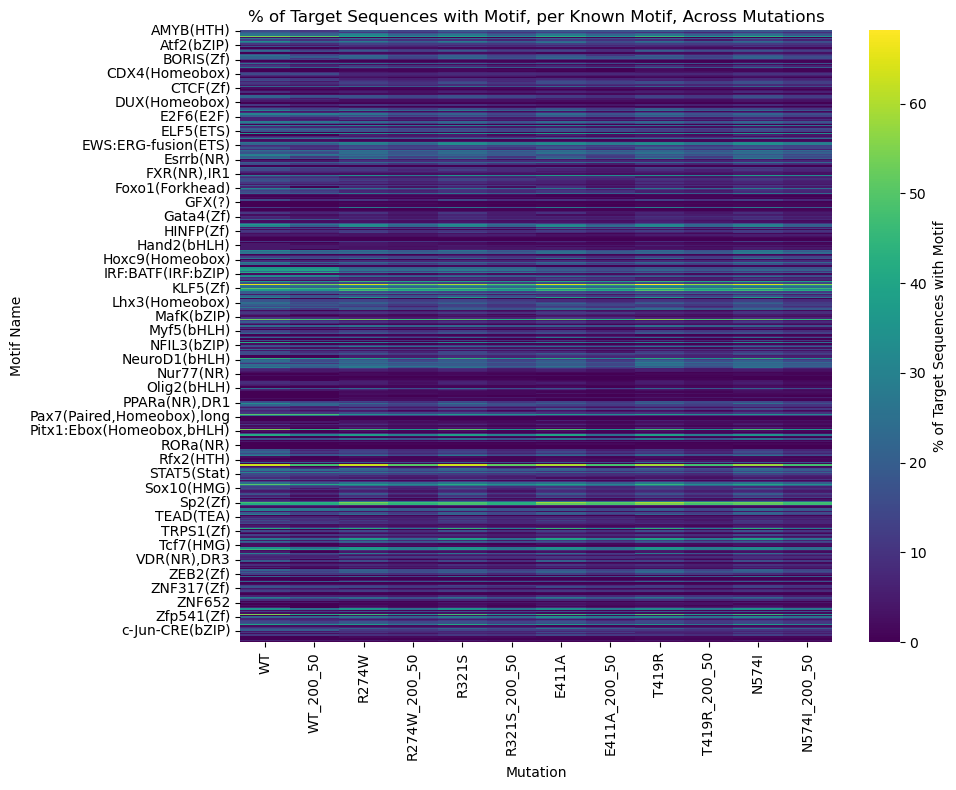

In [852]:
plt.figure(figsize=(10, 8))
sns.heatmap(df_target_pivot, cmap='viridis', cbar_kws={'label': '% of Target Sequences with Motif'})
plt.title('% of Target Sequences with Motif, per Known Motif, Across Mutations')
plt.xlabel('Mutation')
plt.ylabel('Motif Name')
plt.tight_layout()
plt.show()



In [ ]:
n_motifs = df_target_pivot.shape[0]
height_per_motif = 0.25 
fig_height = max(8, n_motifs * height_per_motif)  # min height 8
fig_width = 10

g = sns.clustermap(
    df_target_pivot,
    method='average',
    metric='euclidean',
    cmap='viridis',
    cbar=True,
    cbar_pos=(0.90, 0.05, 0.03, 0.3),
    dendrogram_ratio=0.1,
    figsize=(fig_width, fig_height)
)

# Update motif names in the index
g.figure.suptitle('% of Target Sequences with Motif, per Known Motif, Across Mutations (Hierachical clustering)', y=1.02)
g.ax_heatmap.set_xlabel('Mutation')
g.ax_heatmap.set_ylabel('Motif Name')

plt.show()

**Filter by motifs with significant differences across mutations**

Show only the motifs that, as a result of the previous analysis, were found to be significant in some mutations and non-significant in others.

In [915]:
motifs_sig = df_pivot_bool_filtered.index

In [917]:
len(motifs_sig)

28

There are 28 motifs meeting this criteria.

Shorten the motif names.

In [918]:
motifs_sig = motifs_sig.map(lambda x: x.split("/",1)[0])

In [919]:
motifs_sig

Index(['AP-1(bZIP)', 'BATF(bZIP)', 'Brn2(POU,Homeobox)', 'DMRT1(DM)',
       'DUX(Homeobox)', 'Emx2(Homeobox)', 'FOXK2(Forkhead)', 'FOXP1(Forkhead)',
       'Fosl2(bZIP)', 'Foxo3(Forkhead)', 'Fra2(bZIP)', 'GATA3(Zf),DR4',
       'IRF:BATF(IRF:bZIP)', 'Jun-AP1(bZIP)', 'JunB(bZIP)', 'KLF14(Zf)',
       'Lhx2(Homeobox)', 'NFkB-p65(RHD)', 'NFkB-p65-Rel(RHD)',
       'NFkB2-p52(RHD)', 'PRDM1(Zf)', 'Phox2a(Homeobox)', 'STAT1(Stat)',
       'STAT5(Stat)', 'Stat3(Stat)', 'Stat3+il21(Stat)', 'Tbx20(T-box)',
       'Zic2(Zf)'],
      dtype='object', name='Motif Name')

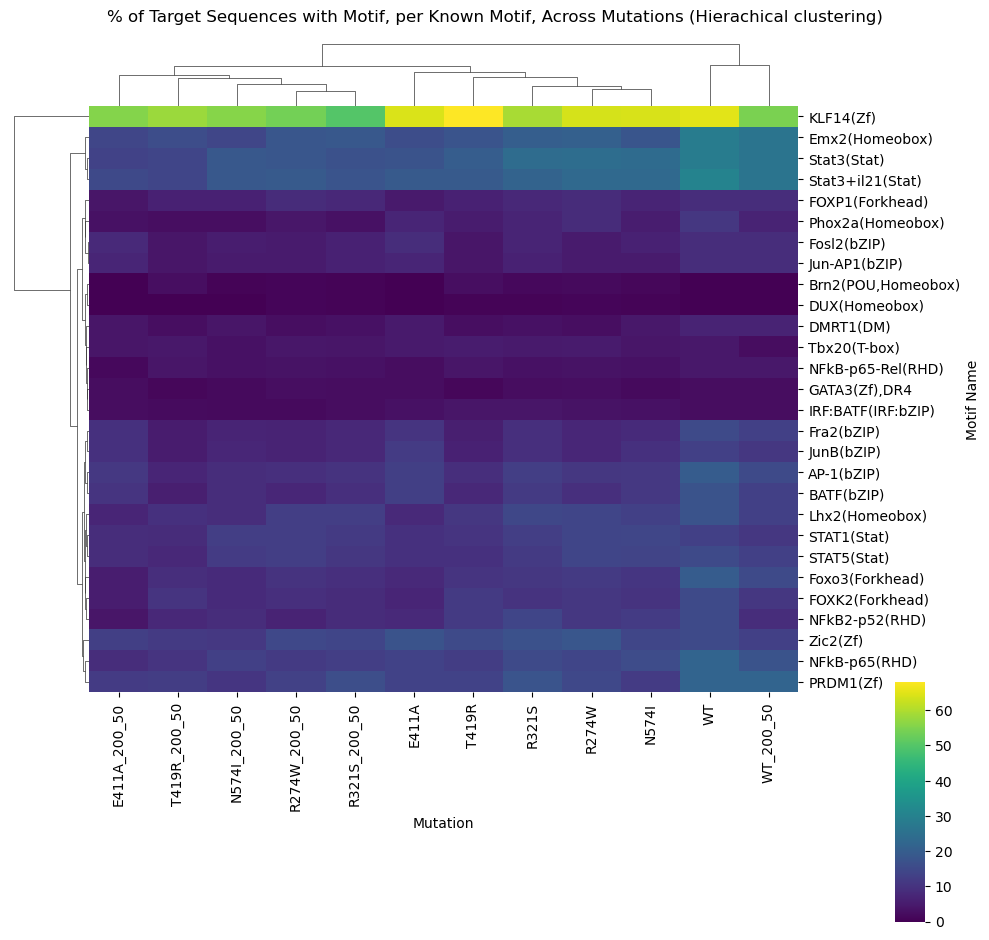

In [924]:
g = sns.clustermap(
    df_target_pivot[df_target_pivot.index.isin(motifs_sig)],
    method='average',
    metric='euclidean',
    cmap='viridis',
    cbar=True,
    cbar_pos=(0.90, 0.-0.12, 0.03, 0.3),
    dendrogram_ratio=0.1,
    figsize=(10, 8)
)

# Update motif names in the index
g.figure.suptitle('% of Target Sequences with Motif, per Known Motif, Across Mutations (Hierachical clustering)', y=1.02)
g.ax_heatmap.set_xlabel('Mutation')
g.ax_heatmap.set_ylabel('Motif Name')

plt.show()

**Filter motifs by percentage**

Filter out motifs present in < 10 % of target sequences for all mutations and WT.

(This was a test, but the results are not very interesting.)

In [782]:
df_targetpercent.shape

(471, 13)

In [804]:
df_targetpercent.columns.difference(["Motif Name"])

Index(['E411A', 'E411A_200_50', 'N574I', 'N574I_200_50', 'R274W',
       'R274W_200_50', 'R321S', 'R321S_200_50', 'T419R', 'T419R_200_50', 'WT',
       'WT_200_50'],
      dtype='object')

In [805]:
df_targetpercent_filtered = df_targetpercent[df_targetpercent[df_targetpercent.columns.difference(["Motif Name"])].astype(float).le(10).any(axis=1)]

In [806]:
df_targetpercent_filtered.shape

(339, 13)

In [807]:
df_target_filtered_pivot = df_targetpercent_filtered.set_index('Motif Name')

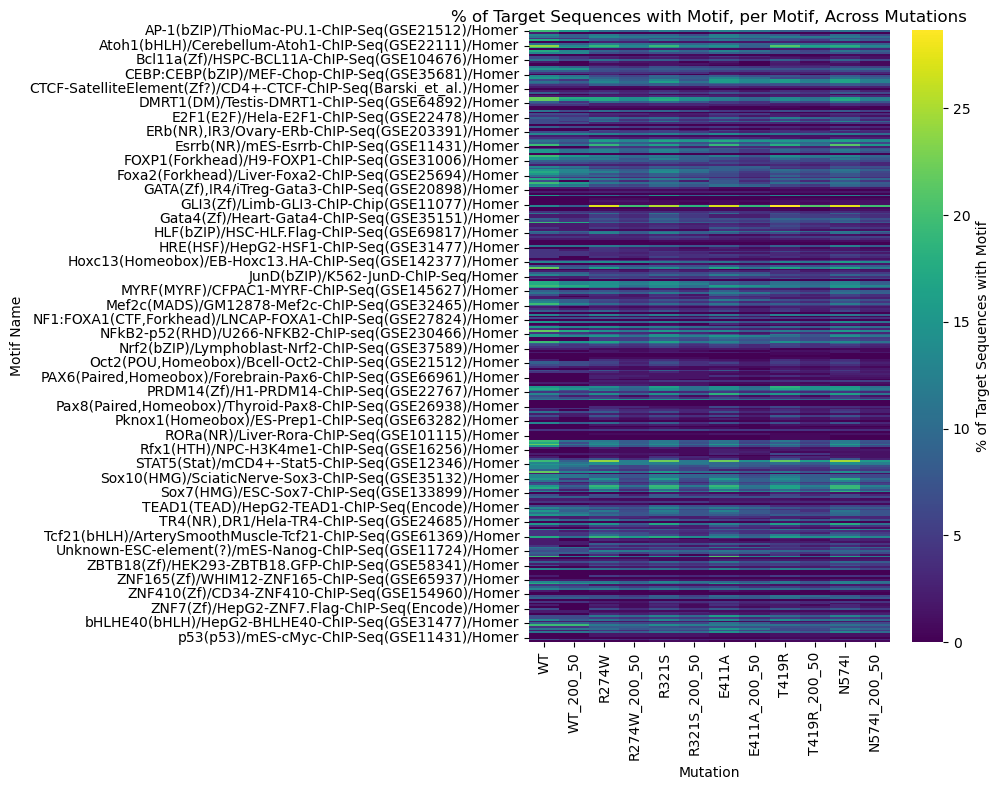

In [808]:
plt.figure(figsize=(10, 8))
sns.heatmap(df_target_filtered_pivot, cmap='viridis', cbar_kws={'label': '% of Target Sequences with Motif'})
plt.title('% of Target Sequences with Motif, per Motif, Across Mutations')
plt.xlabel('Mutation')
plt.ylabel('Motif Name')
plt.tight_layout()
plt.show()

### De novo significant motifs

HOMER seems to mark as "possible false possitive" the de novo motifs with p-value <= 1e-11.

In [56]:
def parse_denovo_motifs(file_path):
    # Initialize lists to store parsed data
    data = {
        'Consensus': [],
        'Motif_Name': [],
        'Best_Guess': [],
        'Score': [],
        'Log_Pvalue': [],
        'Qvalue': [],
        'Target_Percent': [],
        'Background_Percent': [],
        'Pvalue': []
    }
    
    # Read the file
    with open(file_path, 'r') as f:
        for line in f:
            if line.startswith('>'):
                # Split the header line
                parts = line.strip().split('\t')
                if len(parts) < 6:
                    continue  # Skip malformed lines
                
                # Extract fields
                consensus = parts[0][1:]  # Remove '>'
                motif_info = parts[1].split(',')
                motif_name = motif_info[0]
                best_guess = motif_info[1].replace("BestGuess:", "") if len(motif_info) > 1 else 'Unknown'
                score = float(parts[2])
                log_pvalue = float(parts[3])
                qvalue = float(parts[4])
                
                # Parse target and background stats
                stats = parts[5].split(',')
                target_info = stats[0].split(':')[1].split('(')
                target_count = float(target_info[0])
                target_percent = float(target_info[1].rstrip('%)'))
                bg_info = stats[1].split(':')[1].split('(')
                bg_count = float(bg_info[0])
                bg_percent = float(bg_info[1].rstrip('%)'))
                pvalue = parts[5].split('P:')[1]
                
                # Append to data
                data['Consensus'].append(consensus)
                data['Motif_Name'].append(motif_name)
                data['Best_Guess'].append(best_guess)
                data['Score'].append(score)
                data['Log_Pvalue'].append(log_pvalue)
                data['Qvalue'].append(qvalue)
                data['Target_Percent'].append(target_percent)
                data['Background_Percent'].append(bg_percent)
                data['Pvalue'].append(pvalue)
    
    # Create DataFrame
    df = pd.DataFrame(data)
    return df

In [57]:
novo_motif_dfs = {}

for col in up_cols:
    key_motifs = f"{col}_motifs"
    key_motifs_200_50 = f"{col}_motifs_200_50"

    print(key_motifs)
    novo_motif_dfs[key_motifs] = parse_denovo_motifs(f"up_{col}/nonRedundant.motifs")
    print(novo_motif_dfs[key_motifs].shape)
    
    print(key_motifs_200_50)
    novo_motif_dfs[key_motifs_200_50] = parse_denovo_motifs(f"up_{col}_200_50/nonRedundant.motifs")
    print(novo_motif_dfs[key_motifs_200_50].shape)

WT_motifs
(32, 9)
WT_motifs_200_50
(12, 9)
R274W_motifs
(18, 9)
R274W_motifs_200_50
(16, 9)
R321S_motifs
(34, 9)
R321S_motifs_200_50
(13, 9)
E411A_motifs
(40, 9)
E411A_motifs_200_50
(16, 9)
T419R_motifs
(36, 9)
T419R_motifs_200_50
(28, 9)
N574I_motifs
(40, 9)
N574I_motifs_200_50
(14, 9)


In [58]:
novo_motif_dfs["WT_motifs"].head()


,Consensus,Motif_Name,Best_Guess,Score,Log_Pvalue,Qvalue,Target_Percent,Background_Percent,Pvalue
0,GAAACTGAAA,1-GAAACTGAAA,Irf1/MA0050.4/Jaspar(0.981),10.295289,-38.312700,0.0,36.96,2.05,1e-16
1,ACACCCTC,1-ACACCCTC,EKLF(Zf)/Erythrocyte-Klf1-ChIP-Seq(GSE20478)/H...,7.419771,-27.502651,0.0,47.83,8.09,1e-11
2,CGGRTGTCTGGT,2-CGGRTGTCTGGT,PB0060.1_Smad3_1/Jaspar(0.723),8.895358,-23.545279,0.0,26.09,1.93,1e-10
3,CTGSASCTCTAA,3-CTGSASCTCTAA,ZNF135/MA1587.1/Jaspar(0.592),10.310263,-23.472361,0.0,13.04,0.13,1e-10
4,CACCAGTTTT,3-CACCAGTTTT,GRHL1/MA0647.2/Jaspar(0.652),11.068204,-23.368651,0.0,17.39,0.48,1e-10


In [59]:
df_pivot.columns

Index(['WT', 'WT_200_50', 'R274W', 'R274W_200_50', 'R321S', 'R321S_200_50',
       'E411A', 'E411A_200_50', 'T419R', 'T419R_200_50', 'N574I',
       'N574I_200_50'],
      dtype='object')

In [60]:
# Initialize an empty list to collect data
motif_pvalues = []

# Get unique motifs and collect P-values
for df_name in novo_motif_dfs.keys():
    # Convert Pvalue to numeric, handling scientific notation
    novo_motif_dfs[df_name]["Pvalue"] = pd.to_numeric(novo_motif_dfs[df_name]["Pvalue"])
    # Ensure the column contains only strings before applying .str
    novo_motif_dfs[df_name]["Best_Guess"] = novo_motif_dfs[df_name]["Best_Guess"].str.split("/").str[:2]
    novo_motif_dfs[df_name]["Best_Guess"] = novo_motif_dfs[df_name]["Best_Guess"].apply(lambda x: "/".join(map(str, x)))
    
    # Filter for significant motifs (P-value < 1e-11)
    filtered_df = novo_motif_dfs[df_name][["Best_Guess", "Pvalue"]].drop_duplicates()
    # Rename Pvalue column to the DataFrame name
    filtered_df = filtered_df.rename(columns={"Pvalue": df_name})
    filtered_df.columns = filtered_df.columns.str.replace('_motifs', '')
    
    # Append to list
    motif_pvalues.append(filtered_df)

# Merge all DataFrames on Best_Guess using outer join
denovo_sig = motif_pvalues[0]
for df in motif_pvalues[1:]:
    denovo_sig = denovo_sig.merge(df, on="Best_Guess", how="outer")

# Set Best_Guess as index
denovo_sig = denovo_sig.set_index("Best_Guess")

denovo_sig.shape



(137, 12)

In [61]:
denovo_sig.head(20)

,WT,WT_200_50,R274W,R274W_200_50,R321S,R321S_200_50,E411A,E411A_200_50,T419R,T419R_200_50,N574I,N574I_200_50
Best_Guess,,,,,,,,,,,,
AP-2alpha(AP2)/Hela-AP2alpha-ChIP-Seq(GSE31477),1.000000e-05,NaN,NaN,1.000000e-09,NaN,NaN,NaN,NaN,NaN,1.000000e-08,NaN,NaN
Ahr::Arnt/MA0006.2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000e-12,NaN,NaN,NaN
Arntl/MA0603.2,NaN,1.000000e-07,NaN,NaN,NaN,NaN,1.000000e-09,1.000000e-09,NaN,1.000000e-07,NaN,NaN
BARX1/MA0875.2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000e-04,NaN,NaN,NaN
BATF3/MA0835.3,NaN,1.000000e-05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000e-05,NaN,NaN
CEBP:AP1(bZIP)/ThioMac-CEBPb-ChIP-Seq(GSE21512),1.000000e-03,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CREB3L1/MA0839.2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000e-07
CREB3L4/MA1474.2,NaN,NaN,NaN,NaN,NaN,NaN,1.000000e-10,NaN,NaN,NaN,NaN,NaN
Dlx2/MA0885.3,NaN,NaN,NaN,NaN,NaN,1.000000e-12,NaN,NaN,1.000000e-08,NaN,1.000000e-09,NaN


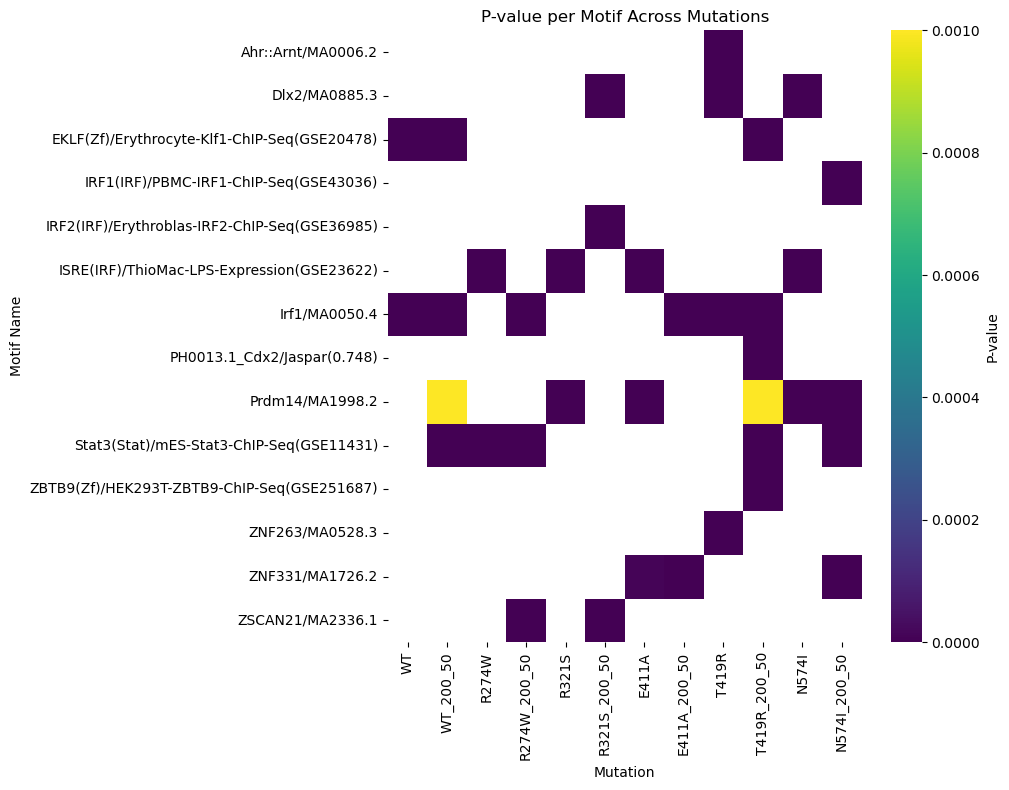

In [62]:
denovo_sig_filtered = denovo_sig[denovo_sig[denovo_sig.columns].le(1e-11).any(axis=1)]

denovo_sig_filtered = denovo_sig_filtered[~denovo_sig_filtered.index.duplicated(keep='first')]

plt.figure(figsize=(10, 8))
sns.heatmap(denovo_sig_filtered, cmap='viridis', cbar_kws={'label': 'P-value'})
plt.title('P-value per Motif Across Mutations')
plt.xlabel('Mutation')
plt.ylabel('Motif Name')
plt.tight_layout()
plt.show()

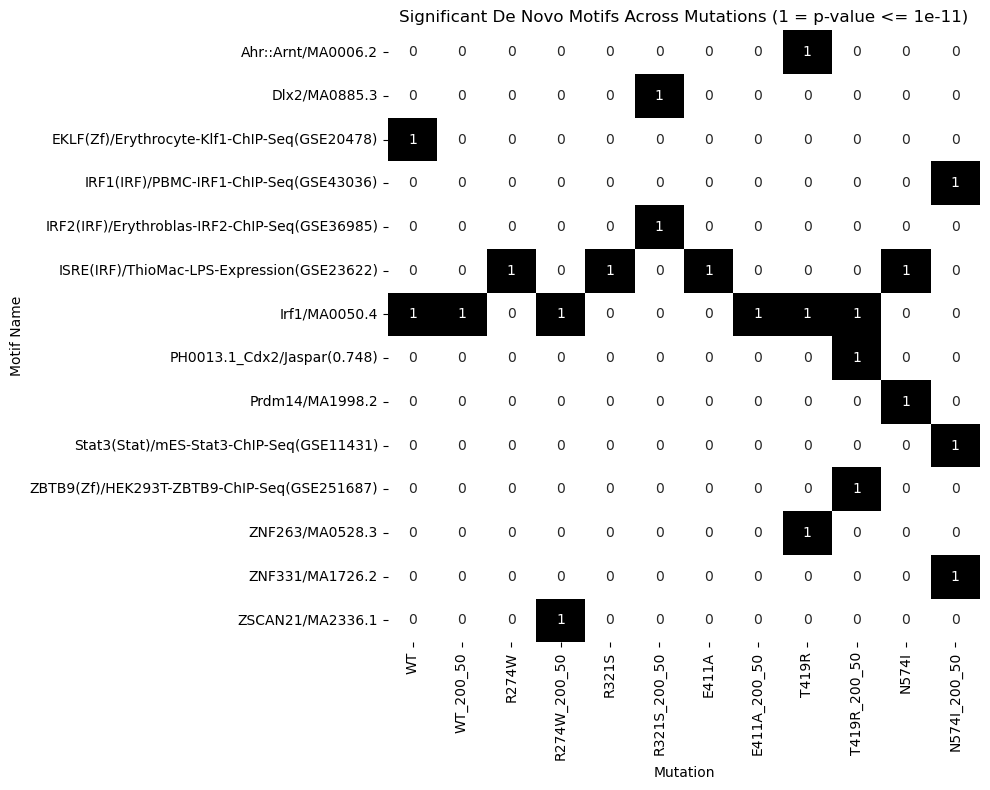

In [63]:
denovo_sig_filtered_bool = denovo_sig_filtered.copy()
denovo_sig_filtered_bool[df_pivot.columns] = np.where(denovo_sig_filtered[df_pivot.columns] <= 1e-11, 1, 0)

plt.figure(figsize=(10, 8))
sns.heatmap(denovo_sig_filtered_bool, annot=True, cmap='binary', cbar=False)
plt.title('Significant De Novo Motifs Across Mutations (1 = p-value <= 1e-11)')
plt.xlabel('Mutation')
plt.ylabel('Motif Name')
plt.tight_layout()
plt.show()

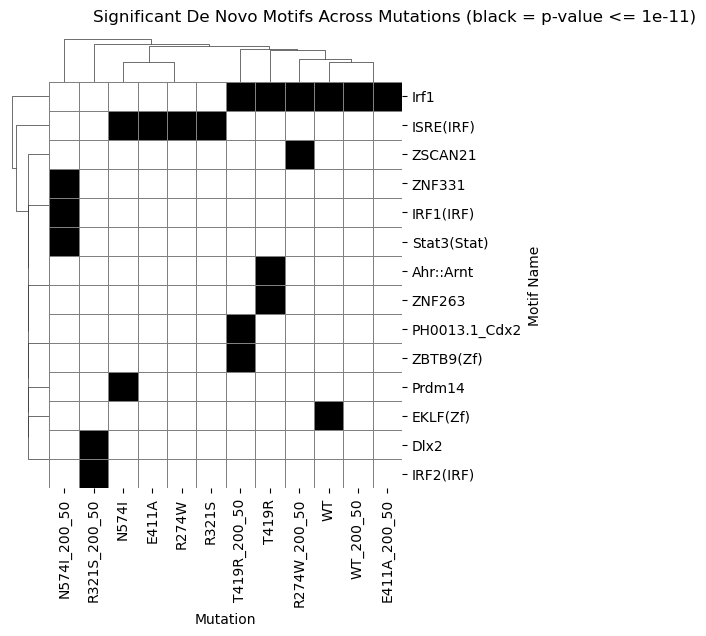

In [67]:
g = sns.clustermap(
    denovo_sig_filtered_bool,
    method='average',
    metric='euclidean',
    cmap='binary',
    annot=False,
    lw=0.5,
    linecolor="gray",
    cbar=False,
    cbar_pos=None,
    dendrogram_ratio=0.1,
    figsize=(8, 6)
)

# Update motif names in the index
g.ax_heatmap.set_yticklabels([label.get_text().split("/", 1)[0] for label in g.ax_heatmap.get_yticklabels()])
g.figure.suptitle('Significant De Novo Motifs Across Mutations (black = p-value <= 1e-11)', y=1.02)  # Adjust y for positioning
g.ax_heatmap.set_xlabel('Mutation')
g.ax_heatmap.set_ylabel('Motif Name')

plt.show()

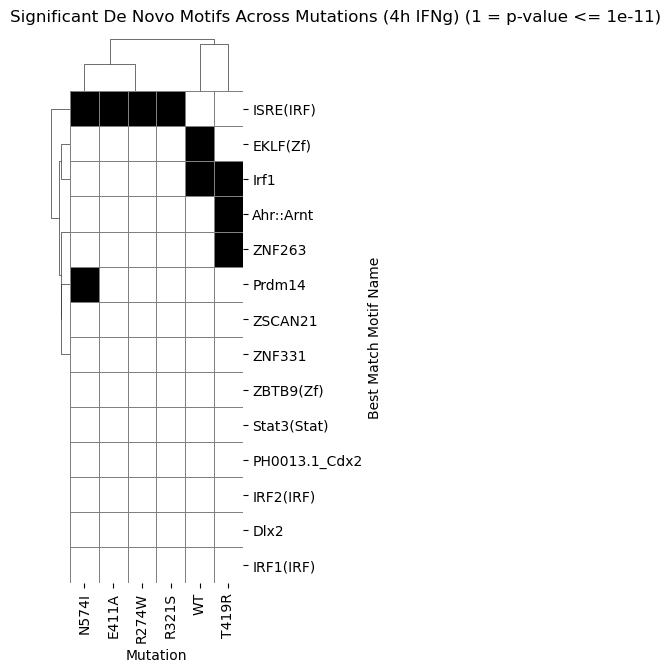

In [38]:
# Filter columns to exclude mutations ending in '_200_50'
filtered_columns = [col for col in denovo_sig_filtered_bool.columns if not col.endswith('_200_50')]
denovo_sig_filtered_bool_subset = denovo_sig_filtered_bool[filtered_columns]

# Create the clustermap
g = sns.clustermap(
    denovo_sig_filtered_bool_subset,
    method='average',
    metric='euclidean',
    cmap='binary',
    annot=False,
    lw=0.5,
    linecolor="gray",
    cbar=False,
    cbar_pos=None,
    dendrogram_ratio=0.1,
    figsize=(6, 6)
)

# Update motif names in the index
g.ax_heatmap.set_yticklabels([label.get_text().split("/", 1)[0] for label in g.ax_heatmap.get_yticklabels()])
g.figure.suptitle('Significant De Novo Motifs Across Mutations (4h IFNg) (1 = p-value <= 1e-11)', y=1.02) 
g.ax_heatmap.set_xticklabels([label.get_text() for label in g.ax_heatmap.get_xticklabels()], rotation=90)
g.ax_heatmap.set_xlabel('Mutation')
g.ax_heatmap.set_ylabel('Best Match Motif Name')

plt.show()

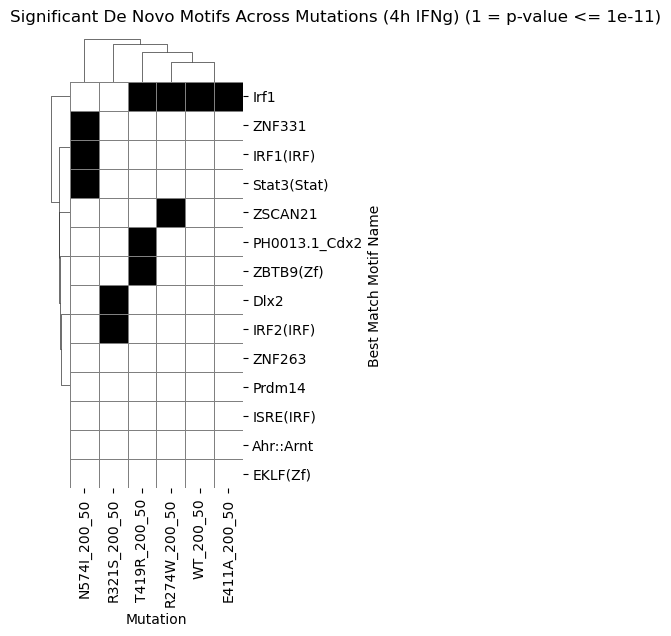

In [ ]:
# Filter columns to include only mutations ending in '_200_50'
filtered_columns = [col for col in denovo_sig_filtered_bool.columns if col.endswith('_200_50')]
denovo_sig_filtered_bool_subset = denovo_sig_filtered_bool[filtered_columns]

# Create the clustermap
g = sns.clustermap(
    denovo_sig_filtered_bool_subset,
    method='average',
    metric='euclidean',
    cmap='binary',
    annot=False,
    lw=0.5,
    linecolor="gray",
    cbar=False,
    cbar_pos=None,
    dendrogram_ratio=0.1,
    figsize=(6, 6)
)

# Update motif names in the index
g.ax_heatmap.set_yticklabels([label.get_text().split("/", 1)[0] for label in g.ax_heatmap.get_yticklabels()])
g.figure.suptitle('Significant De Novo Motifs Across Mutations (4h IFNg) (1 = p-value <= 1e-11)', y=1.02)  # Adjust y for positioning
g.ax_heatmap.set_xlabel('Mutation')
g.ax_heatmap.set_ylabel('Best Match Motif Name')

plt.show()

# ChIPseq peaks comparison

ChIPseq data derived from Robertson G, Hirst M, Bainbridge M, Bilenky M et al. Genome-wide profiles of STAT1 DNA association using chromatin immunoprecipitation and massively parallel sequencing. Nat Methods 2007 Aug;4(8):651-7.

Note that this study used genome hg18, while Giovannozzi et al. (2021) used hg19 to align their RNAseq reads. The coordinates in the peak file are highly dependent on the reference genome used, unlike the gene identifiers resulting from the 2021 study, which should be mostly constant. Consequently, the peak analysis is performed with hg18 and gene motif analysis (previou sections) was performed with the default hg19. The comparison between the identified motifs should not be an issue, as these are not coordinate-dependent and the genome differences were taken into account in the previous steps.

## Load peaks data (bed)

In [394]:
! gzip -dkf ENCFF002CTG.bed.gz

In [395]:
! cat ENCFF002CTG.bed | head

chr2	191884805	191885418	.	1000	.	1125.19089257037	-1	4.36636691561264	320
chr14	24630106	24630704	.	1000	.	1067.72931075946	-1	4.36636691561264	291
chr1	150534389	150534974	.	1000	.	1050.96281007288	-1	4.36636691561264	292
chr17	40540548	40541132	.	1000	.	970.966586915117	-1	4.36636691561264	277
chr5	131826313	131826888	.	1000	.	969.338428335127	-1	4.36636691561264	277
chr15	45020748	45021367	.	1000	.	949.921536323968	-1	4.36636691561264	296
chr16	28543321	28544022	.	1000	.	888.216935005481	-1	4.36636691561264	448
chr16	10922654	10923202	.	1000	.	885.780123187656	-1	4.36636691561264	264
chr3	156892482	156893033	.	1000	.	867.668868183297	-1	4.36636691561264	286
chr6	32821320	32821996	.	1000	.	859.700133001421	-1	4.36636691561264	307
cat: write error: Broken pipe


Adapt BED file to input it to Homer:

- Column1: chromosome
 
- Column2: starting position
 
- Column3: ending position
 
- Column4: Unique Peak ID
 
- Column5: not used
 
- Column6: Strand

In [396]:
! cat ENCFF002CTG.bed | cut -f 1-6 > ENCFF002CTG_peaks.bed

In [397]:
! cat ENCFF002CTG_peaks.bed | head

chr2	191884805	191885418	.	1000	.
chr14	24630106	24630704	.	1000	.
chr1	150534389	150534974	.	1000	.
chr17	40540548	40541132	.	1000	.
chr5	131826313	131826888	.	1000	.
chr15	45020748	45021367	.	1000	.
chr16	28543321	28544022	.	1000	.
chr16	10922654	10923202	.	1000	.
chr3	156892482	156893033	.	1000	.
chr6	32821320	32821996	.	1000	.
cat: write error: Broken pipe


Add peak ids.

In [398]:
peaks_df = pd.read_csv("ENCFF002CTG_peaks.bed", sep="\t", header=None)

In [399]:
peaks_df.head()

,0,1,2,3,4,5
0,chr2,191884805,191885418,.,1000,.
1,chr14,24630106,24630704,.,1000,.
2,chr1,150534389,150534974,.,1000,.
3,chr17,40540548,40541132,.,1000,.
4,chr5,131826313,131826888,.,1000,.


In [400]:
peaks_df[3] = peaks_df.index

In [401]:
peaks_df.head()

,0,1,2,3,4,5
0,chr2,191884805,191885418,0,1000,.
1,chr14,24630106,24630704,1,1000,.
2,chr1,150534389,150534974,2,1000,.
3,chr17,40540548,40541132,3,1000,.
4,chr5,131826313,131826888,4,1000,.


In [402]:
peaks_df.to_csv("ENCFF002CTG_peaks_id.bed", sep="\t", header=None, index=False)

## Annotate

This is not necessary for the motif analysis.

In [404]:
! annotatePeaks.pl ENCFF002CTG_peaks.bed hg18 > ENCFF002CTG_peaks_ann.tsv


	Peak file = ENCFF002CTG_peaks.bed
	Genome = hg18
	Organism = human
	Peak/BED file conversion summary:
		BED/Header formatted lines: 16158
		peakfile formatted lines: 0
		Duplicated Peak IDs: 16157

	Peak File Statistics:
		Total Peaks: 16158
		Redundant Peak IDs: 0
		Peaks lacking information: 0 (need at least 5 columns per peak)
		Peaks with misformatted coordinates: 0 (should be integer)
		Peaks with misformatted strand: 0 (should be either +/- or 0/1)

	Peak file looks good!

	Reading Positions...
	-----------------------
	offset=0
	Finding Closest TSS...
	Annotating:.......................
		Annotation	Number of peaks	Total size (bp)	Log2 Ratio (obs/exp)	LogP enrichment (+values depleted)
		3UTR	219.0	27008377	0.600	-19.324
		miRNA	1.0	109259	0.775	-0.815
		ncRNA	64.0	7030917	0.767	-9.822
		TTS	246.0	32241910	0.513	-16.509
		pseudo	6.0	2050984	-0.870	2.528
		Exon	345.0	37350290	0.788	-46.933
		Intron	7886.0	1266312506	0.220	-159.440
		Intergenic	7059.0	1610613456	-0.287	303.712
	

In [405]:
! cat ENCFF002CTG_peaks_ann.tsv | head

PeakID (cmd=annotatePeaks.pl ENCFF002CTG_peaks.bed hg18)	Chr	Start	End	Strand	Peak Score	Focus Ratio/Region Size	Annotation	Detailed Annotation	Distance to TSS	Nearest PromoterID	Entrez ID	Nearest Unigene	Nearest Refseq	Nearest Ensembl	Gene Name	Gene Alias	Gene Description	Gene Type
1-674	chr16	84189859	84190139	+	1000	NA	Intergenic	Intergenic	-12517	NM_001134473	23199		NM_014615	ENSG00000131149	GSE1	CRHSP24|KIAA0182	Gse1 coiled-coil protein	protein-coding
1-828	chr12	109531341	109531485	+	1000	NA	Intergenic	Intergenic	-4904	NM_001173976	79600		NM_024549	ENSG00000204852	TCTN1	JBTS13|TECT1	tectonic family member 1	protein-coding
1-580	chr3	177477063	177477422	+	1000	NA	Intergenic	L1ME3A|LINE|L1	-238343	NR_107017	102465858		NR_107017	ENSG00000283333	MIR7977	hsa-mir-7977	microRNA 7977	ncRNA
1-668	chr1	66727907	66728189	+	1000	NA	Intergenic	Intergenic	-43584	NM_001376535	84251		NM_032291	ENSG00000118473	SGIP1	-	SH3GL interacting endocytic adaptor 1	protein-coding
1-723	chr3	146262228	14626

In [406]:
df_ann = pd.read_csv('ENCFF002CTG_peaks_ann.tsv',sep='\t')

In [407]:
df_ann.columns

Index(['PeakID (cmd=annotatePeaks.pl ENCFF002CTG_peaks.bed hg18)', 'Chr',
       'Start', 'End', 'Strand', 'Peak Score', 'Focus Ratio/Region Size',
       'Annotation', 'Detailed Annotation', 'Distance to TSS',
       'Nearest PromoterID', 'Entrez ID', 'Nearest Unigene', 'Nearest Refseq',
       'Nearest Ensembl', 'Gene Name', 'Gene Alias', 'Gene Description',
       'Gene Type'],
      dtype='object')

In [408]:
df_ann.shape

(16158, 19)

In [409]:
df_ann.head()

,PeakID (cmd=annotatePeaks.pl ENCFF002CTG_peaks.bed hg18),Chr,Start,End,Strand,Peak Score,Focus Ratio/Region Size,Annotation,Detailed Annotation,Distance to TSS,Nearest PromoterID,Entrez ID,Nearest Unigene,Nearest Refseq,Nearest Ensembl,Gene Name,Gene Alias,Gene Description,Gene Type
0,1-674,chr16,84189859,84190139,+,1000,NaN,Intergenic,Intergenic,-12517,NM_001134473,23199.0,NaN,NM_014615,ENSG00000131149,GSE1,CRHSP24|KIAA0182,Gse1 coiled-coil protein,protein-coding
1,1-828,chr12,109531341,109531485,+,1000,NaN,Intergenic,Intergenic,-4904,NM_001173976,79600.0,NaN,NM_024549,ENSG00000204852,TCTN1,JBTS13|TECT1,tectonic family member 1,protein-coding
2,1-580,chr3,177477063,177477422,+,1000,NaN,Intergenic,L1ME3A|LINE|L1,-238343,NR_107017,102465858.0,NaN,NR_107017,ENSG00000283333,MIR7977,hsa-mir-7977,microRNA 7977,ncRNA
3,1-668,chr1,66727907,66728189,+,1000,NaN,Intergenic,Intergenic,-43584,NM_001376535,84251.0,NaN,NM_032291,ENSG00000118473,SGIP1,-,SH3GL interacting endocytic adaptor 1,protein-coding
4,1-723,chr3,146262228,146262589,+,1000,NaN,Intergenic,MLT1D-int|LTR|MaLR,1007254,NR_146297,109729161.0,NaN,NR_146297,ENSG00000240032,LNCSRLR,lncRNA-SRLR,lncRNA sorafenib resistance in renal cell carc...,ncRNA


In [410]:
df_ann[df_ann['Gene Type'] == 'protein-coding'].shape

(11380, 19)

## Find ChIPseq peak motifs

In [159]:
! findMotifsGenome.pl ENCFF002CTG_peaks_id.bed hg18 ENCFF002CTG/ -size 250 -p 8


	Position file = ENCFF002CTG_peaks_id.bed
	Genome = hg18
	Output Directory = ENCFF002CTG/
	Fragment size set to 250
	Using 8 CPUs
	Found mset for "human", will check against vertebrates motifs
	Peak/BED file conversion summary:
		BED/Header formatted lines: 16158
		peakfile formatted lines: 0

	Peak File Statistics:
		Total Peaks: 16158
		Redundant Peak IDs: 0
		Peaks lacking information: 0 (need at least 5 columns per peak)
		Peaks with misformatted coordinates: 0 (should be integer)
		Peaks with misformatted strand: 0 (should be either +/- or 0/1)

	Peak file looks good!

	Background files for 250 bp fragments found.
	Custom genome sequence directory: /home/irati/homer/.//data/genomes/hg18//

	Extracting sequences from directory: /home/irati/homer/.//data/genomes/hg18//
	Extracting 1899 sequences from chr1
	Extracting 1108 sequences from chr2
	Extracting 1132 sequences from chr3
	Extracting 417 sequences from chr4
	Extracting 1059 sequences from chr5
	Extracting 930 sequences from c

## Comparison

### WT

In [ ]:
chip_motifs = pd.read_csv("ENCFF002CTG/knownResults.txt", sep="\t")

comparison_chip_wt = pd.merge(WT_motifs_200_50.drop_duplicates(subset="Motif Name"), chip_motifs.drop_duplicates(subset="Motif Name"), on="Motif Name", how="outer", suffixes=("_WT", "_chip"))

In [419]:
comparison_chip_wt.shape

(471, 17)

In [418]:
comparison_chip_wt.columns

Index(['Motif Name', 'Consensus_WT', 'P-value_WT', 'Log P-value_WT',
       'q-value (Benjamini)_WT', '# of Target Sequences with Motif(of 46)',
       '% of Target Sequences with Motif_WT',
       '# of Background Sequences with Motif(of 42368)',
       '% of Background Sequences with Motif_WT', 'Consensus_chip',
       'P-value_chip', 'Log P-value_chip', 'q-value (Benjamini)_chip',
       '# of Target Sequences with Motif(of 15940)',
       '% of Target Sequences with Motif_chip',
       '# of Background Sequences with Motif(of 84610)',
       '% of Background Sequences with Motif_chip'],
      dtype='object')

**Motifs intersection**

In [420]:
comparison_chip_wt.isna().sum()

Motif Name                                        0
Consensus_WT                                      0
P-value_WT                                        0
Log P-value_WT                                    0
q-value (Benjamini)_WT                            0
# of Target Sequences with Motif(of 46)           0
% of Target Sequences with Motif_WT               0
# of Background Sequences with Motif(of 42368)    0
% of Background Sequences with Motif_WT           0
Consensus_chip                                    0
P-value_chip                                      0
Log P-value_chip                                  0
q-value (Benjamini)_chip                          0
# of Target Sequences with Motif(of 15940)        0
% of Target Sequences with Motif_chip             0
# of Background Sequences with Motif(of 84610)    0
% of Background Sequences with Motif_chip         0
dtype: int64

In [421]:
comparison_chip_wt[(comparison_chip_wt["% of Target Sequences with Motif_WT"] == "0.00%") & (comparison_chip_wt["% of Target Sequences with Motif_chip"] != "0.00%")].shape

(108, 17)

In [422]:
comparison_chip_wt[(comparison_chip_wt["% of Target Sequences with Motif_WT"] == "0.00%") & (comparison_chip_wt["% of Target Sequences with Motif_chip"] != "0.00%")][["% of Target Sequences with Motif_chip", "P-value_chip"]].sort_values("P-value_chip").head(10)

,% of Target Sequences with Motif_chip,P-value_chip
432,0.33%,0.01
120,8.55%,0.10
230,0.96%,0.10
280,0.94%,0.10
269,12.52%,0.10
206,2.99%,0.10
321,1.57%,0.10
300,3.71%,0.10
443,1.28%,0.10
470,0.40%,0.10


In [425]:
comparison_chip_wt[(comparison_chip_wt["% of Target Sequences with Motif_WT"] != "0.00%") & (comparison_chip_wt["% of Target Sequences with Motif_chip"] == "0.00%")].shape

(0, 17)

The same motifs were found in both dataframes, but there are 108 motifs found in the ChIPseq peaks with very low frequency (< 0.01 \%) in the WT upregulated gene promoters. Only one of these is significant in the ChIPseq peaks. There are no motifs that meet the opposity criteria, that is, motifs with very low frequency in ChIPseq peaks. This is to be expected, as the ChIPseq peaks cover all STAT1 binding sites, while the WT dataframe only includes upregulated genes.

**Comparison**

15 motifs are significant in WT upregulated gene promoters and not significant in ChIPseq peaks.

In [431]:
comparison_chip_wt[(comparison_chip_wt["P-value_chip"] > 0.05) & (comparison_chip_wt["P-value_WT"] < 0.05)].shape

(15, 17)

In [426]:
comparison_chip_wt[(comparison_chip_wt["P-value_chip"] > 0.05) & (comparison_chip_wt["P-value_WT"] < 0.05)][["Motif Name", "P-value_WT", "P-value_chip", "% of Target Sequences with Motif_WT", "% of Target Sequences with Motif_chip", "Consensus_chip", "q-value (Benjamini)_WT", "q-value (Benjamini)_chip"]].sort_values("P-value_WT", ascending=True).head(15)

,Motif Name,P-value_WT,P-value_chip,% of Target Sequences with Motif_WT,% of Target Sequences with Motif_chip,Consensus_chip,q-value (Benjamini)_WT,q-value (Benjamini)_chip
183,IRF2(IRF)/Erythroblas-IRF2-ChIP-Seq(GSE36985)/...,1.000000e-14,1.0,34.78%,1.12%,GAAASYGAAASY,0.0000,1.0000
188,ISRE(IRF)/ThioMac-LPS-Expression(GSE23622)/Homer,1.000000e-14,1.0,30.43%,0.75%,AGTTTCASTTTC,0.0000,1.0000
182,IRF1(IRF)/PBMC-IRF1-ChIP-Seq(GSE43036)/Homer,1.000000e-13,1.0,34.78%,1.74%,GAAAGTGAAAGT,0.0000,1.0000
184,IRF3(IRF)/BMDM-Irf3-ChIP-Seq(GSE67343)/Homer,1.000000e-11,1.0,39.13%,4.14%,AGTTTCAKTTTC,0.0000,1.0000
186,IRF8(IRF)/BMDM-IRF8-ChIP-Seq(GSE77884)/Homer,1.000000e-11,1.0,41.30%,3.88%,GRAASTGAAAST,0.0000,0.8146
295,PU.1-IRF(ETS:IRF)/Bcell-PU.1-ChIP-Seq(GSE21512...,1.000000e-04,1.0,47.83%,15.74%,MGGAAGTGAAAC,0.0007,1.0000
461,"bZIP:IRF(bZIP,IRF)/Th17-BatF-ChIP-Seq(GSE39756...",1.000000e-04,1.0,19.57%,6.61%,NAGTTTCABTHTGACTNW,0.0046,0.9500
185,IRF4(IRF)/GM12878-IRF4-ChIP-Seq(GSE32465)/Homer,1.000000e-03,0.1,19.57%,5.61%,ACTGAAACCA,0.0103,0.6620
368,Stat3(Stat)/mES-Stat3-ChIP-Seq(GSE11431)/Homer,1.000000e-03,1.0,26.09%,4.34%,CTTCCGGGAA,0.0193,1.0000
288,PRDM1(Zf)/Hela-PRDM1-ChIP-Seq(GSE31477)/Homer,1.000000e-03,1.0,21.74%,7.40%,ACTTTCACTTTC,0.0236,0.7649


9 motifs are significant in ChIPseq peaks and not significant in WT upregulated gene promoters.

In [430]:
comparison_chip_wt[(comparison_chip_wt["P-value_chip"] < 0.05) & (comparison_chip_wt["P-value_WT"] > 0.05)].shape

(9, 17)

In [432]:
comparison_chip_wt[(comparison_chip_wt["P-value_chip"] < 0.05) & (comparison_chip_wt["P-value_WT"] > 0.05)][["Motif Name", "P-value_WT", "P-value_chip", "% of Target Sequences with Motif_WT", "% of Target Sequences with Motif_chip", "Consensus_chip", "q-value (Benjamini)_WT", "q-value (Benjamini)_chip"]].sort_values("P-value_chip", ascending=True).head(10)

,Motif Name,P-value_WT,P-value_chip,% of Target Sequences with Motif_WT,% of Target Sequences with Motif_chip,Consensus_chip,q-value (Benjamini)_WT,q-value (Benjamini)_chip
247,NFkB2-p52(RHD)/U266-NFKB2-ChIP-seq(GSE230466)/...,1.0,0.000001,8.70%,6.38%,VGGGRATTYCCC,0.9156,0.0004
68,EAR2(NR)/K562-NR2F6-ChIP-Seq(Encode)/Homer,1.0,0.000010,4.35%,18.49%,NRBCARRGGTCA,1.0000,0.0011
140,GSC(Homeobox)/FrogEmbryos-GSC-ChIP-Seq(DRA0005...,1.0,0.001000,6.52%,27.64%,RGGATTAR,1.0000,0.0166
136,GLIS3(Zf)/Thyroid-Glis3.GFP-ChIP-Seq(GSE103297...,1.0,0.001000,8.70%,21.57%,CTCCCTGGGAGGCCN,1.0000,0.0191
121,Foxo1(Forkhead)/RAW-Foxo1-ChIP-Seq(Fan_et_al.)...,1.0,0.010000,26.09%,24.24%,CTGTTTAC,0.8806,0.1823
40,COUP-TFII(NR)/K562-NR2F1-ChIP-Seq(Encode)/Homer,1.0,0.010000,8.70%,19.41%,GKBCARAGGTCA,1.0000,0.1823
249,NPAS2(bHLH)/Liver-NPAS2-ChIP-Seq(GSE39860)/Homer,1.0,0.010000,13.04%,12.82%,KCCACGTGAC,1.0000,0.3015
391,Tbx5(T-box)/HL1-Tbx5.biotin-ChIP-Seq(GSE21529)...,1.0,0.010000,21.74%,42.91%,AGGTGTCA,1.0000,0.1538
432,ZNF382(Zf)/HEK293-ZNF382.GFP-ChIP-Seq(GSE58341...,1.0,0.010000,0.00%,0.33%,GNCTGTASTRNTGBCTCHTT,1.0000,0.2434


### T419R

In [433]:
comparison_chip_T419R = pd.merge(T419R_motifs_200_50.drop_duplicates(subset="Motif Name"), chip_motifs.drop_duplicates(subset="Motif Name"), on="Motif Name", how="outer", suffixes=("_T419R", "_chip"))

In [435]:
comparison_chip_T419R.shape

(471, 17)

In [434]:
comparison_chip_T419R.columns

Index(['Motif Name', 'Consensus_T419R', 'P-value_T419R', 'Log P-value_T419R',
       'q-value (Benjamini)_T419R', '# of Target Sequences with Motif(of 157)',
       '% of Target Sequences with Motif_T419R',
       '# of Background Sequences with Motif(of 45202)',
       '% of Background Sequences with Motif_T419R', 'Consensus_chip',
       'P-value_chip', 'Log P-value_chip', 'q-value (Benjamini)_chip',
       '# of Target Sequences with Motif(of 15940)',
       '% of Target Sequences with Motif_chip',
       '# of Background Sequences with Motif(of 84610)',
       '% of Background Sequences with Motif_chip'],
      dtype='object')

**Motifs intersection**

In [436]:
comparison_chip_T419R.isna().sum()

Motif Name                                        0
Consensus_T419R                                   0
P-value_T419R                                     0
Log P-value_T419R                                 0
q-value (Benjamini)_T419R                         0
# of Target Sequences with Motif(of 157)          0
% of Target Sequences with Motif_T419R            0
# of Background Sequences with Motif(of 45202)    0
% of Background Sequences with Motif_T419R        0
Consensus_chip                                    0
P-value_chip                                      0
Log P-value_chip                                  0
q-value (Benjamini)_chip                          0
# of Target Sequences with Motif(of 15940)        0
% of Target Sequences with Motif_chip             0
# of Background Sequences with Motif(of 84610)    0
% of Background Sequences with Motif_chip         0
dtype: int64

In [437]:
comparison_chip_T419R[(comparison_chip_T419R["% of Target Sequences with Motif_T419R"] == "0.00%") & (comparison_chip_T419R["% of Target Sequences with Motif_chip"] != "0.00%")].shape

(35, 17)

In [438]:
comparison_chip_T419R[(comparison_chip_T419R["% of Target Sequences with Motif_T419R"] == "0.00%") & (comparison_chip_T419R["% of Target Sequences with Motif_chip"] != "0.00%")][["% of Target Sequences with Motif_chip", "P-value_chip"]].sort_values("P-value_chip").head(10)

,% of Target Sequences with Motif_chip,P-value_chip
432,0.33%,0.01
206,2.99%,0.10
230,0.96%,0.10
5,1.90%,1.00
55,0.06%,1.00
56,0.77%,1.00
36,2.26%,1.00
23,0.38%,1.00
72,0.11%,1.00
104,1.23%,1.00


In [439]:
comparison_chip_T419R[(comparison_chip_T419R["% of Target Sequences with Motif_T419R"] != "0.00%") & (comparison_chip_T419R["% of Target Sequences with Motif_chip"] == "0.00%")].shape

(0, 17)

The same motifs were found in both dataframes, but there are 35 motifs found in the ChIPseq peaks with very low frequency (< 0.01 \%) in the T419R upregulated gene promoters. The number of very low frequency motifs is considerably smaller than for the WT set. Only one of these motifs is significant in the ChIPseq peaks. There are no motifs that meet the opposity criteria, that is, motifs with very low frequency in ChIPseq peaks. 

**Comparison**

In [440]:
comparison_chip_T419R[(comparison_chip_T419R["P-value_chip"] > 0.05) & (comparison_chip_T419R["P-value_T419R"] < 0.05)][["Motif Name", "P-value_T419R", "P-value_chip", "% of Target Sequences with Motif_T419R", "% of Target Sequences with Motif_chip", "Consensus_chip", "q-value (Benjamini)_T419R", "q-value (Benjamini)_chip"]].shape

(19, 8)

In [441]:
comparison_chip_T419R[(comparison_chip_T419R["P-value_chip"] > 0.05) & (comparison_chip_T419R["P-value_T419R"] < 0.05)][["Motif Name", "P-value_T419R", "P-value_chip", "% of Target Sequences with Motif_T419R", "% of Target Sequences with Motif_chip", "Consensus_chip", "q-value (Benjamini)_T419R", "q-value (Benjamini)_chip"]].sort_values("P-value_T419R", ascending=True).head(20)

,Motif Name,P-value_T419R,P-value_chip,% of Target Sequences with Motif_T419R,% of Target Sequences with Motif_chip,Consensus_chip,q-value (Benjamini)_T419R,q-value (Benjamini)_chip
188,ISRE(IRF)/ThioMac-LPS-Expression(GSE23622)/Homer,1.000000e-15,1.0,13.38%,0.75%,AGTTTCASTTTC,0.0000,1.0000
183,IRF2(IRF)/Erythroblas-IRF2-ChIP-Seq(GSE36985)/...,1.000000e-14,1.0,15.29%,1.12%,GAAASYGAAASY,0.0000,1.0000
182,IRF1(IRF)/PBMC-IRF1-ChIP-Seq(GSE43036)/Homer,1.000000e-14,1.0,15.92%,1.74%,GAAAGTGAAAGT,0.0000,1.0000
184,IRF3(IRF)/BMDM-Irf3-ChIP-Seq(GSE67343)/Homer,1.000000e-11,1.0,18.47%,4.14%,AGTTTCAKTTTC,0.0000,1.0000
186,IRF8(IRF)/BMDM-IRF8-ChIP-Seq(GSE77884)/Homer,1.000000e-08,1.0,18.47%,3.88%,GRAASTGAAAST,0.0000,0.8146
370,T1ISRE(IRF)/ThioMac-Ifnb-Expression/Homer,1.000000e-06,1.0,3.18%,0.12%,ACTTTCGTTTCT,0.0000,1.0000
295,PU.1-IRF(ETS:IRF)/Bcell-PU.1-ChIP-Seq(GSE21512...,1.000000e-05,1.0,32.48%,15.74%,MGGAAGTGAAAC,0.0003,1.0000
461,"bZIP:IRF(bZIP,IRF)/Th17-BatF-ChIP-Seq(GSE39756...",1.000000e-04,1.0,9.55%,6.61%,NAGTTTCABTHTGACTNW,0.0034,0.9500
288,PRDM1(Zf)/Hela-PRDM1-ChIP-Seq(GSE31477)/Homer,1.000000e-03,1.0,12.10%,7.40%,ACTTTCACTTTC,0.0305,0.7649
95,Emx2(Homeobox)/Cortex-Emx2-ChIP-Seq(GSE183130)...,1.000000e-03,1.0,15.92%,16.87%,NVCTAATTAG,0.0130,1.0000


In [442]:
comparison_chip_T419R[(comparison_chip_T419R["P-value_chip"] < 0.05) & (comparison_chip_T419R["P-value_T419R"] > 0.05)][["Motif Name", "P-value_T419R", "P-value_chip", "% of Target Sequences with Motif_T419R", "% of Target Sequences with Motif_chip", "Consensus_chip", "q-value (Benjamini)_T419R", "q-value (Benjamini)_chip"]].shape

(9, 8)

In [443]:
comparison_chip_T419R[(comparison_chip_T419R["P-value_chip"] < 0.05) & (comparison_chip_T419R["P-value_T419R"] > 0.05)][["Motif Name", "P-value_T419R", "P-value_chip", "% of Target Sequences with Motif_T419R", "% of Target Sequences with Motif_chip", "Consensus_chip", "q-value (Benjamini)_T419R", "q-value (Benjamini)_chip"]].sort_values("P-value_chip", ascending=True).head(10)

,Motif Name,P-value_T419R,P-value_chip,% of Target Sequences with Motif_T419R,% of Target Sequences with Motif_chip,Consensus_chip,q-value (Benjamini)_T419R,q-value (Benjamini)_chip
247,NFkB2-p52(RHD)/U266-NFKB2-ChIP-seq(GSE230466)/...,1.0,0.000001,7.64%,6.38%,VGGGRATTYCCC,0.7970,0.0004
68,EAR2(NR)/K562-NR2F6-ChIP-Seq(Encode)/Homer,1.0,0.000010,8.28%,18.49%,NRBCARRGGTCA,1.0000,0.0011
140,GSC(Homeobox)/FrogEmbryos-GSC-ChIP-Seq(DRA0005...,1.0,0.001000,4.46%,27.64%,RGGATTAR,1.0000,0.0166
136,GLIS3(Zf)/Thyroid-Glis3.GFP-ChIP-Seq(GSE103297...,1.0,0.001000,21.02%,21.57%,CTCCCTGGGAGGCCN,1.0000,0.0191
121,Foxo1(Forkhead)/RAW-Foxo1-ChIP-Seq(Fan_et_al.)...,0.1,0.010000,22.93%,24.24%,CTGTTTAC,0.3277,0.1823
40,COUP-TFII(NR)/K562-NR2F1-ChIP-Seq(Encode)/Homer,1.0,0.010000,12.74%,19.41%,GKBCARAGGTCA,1.0000,0.1823
249,NPAS2(bHLH)/Liver-NPAS2-ChIP-Seq(GSE39860)/Homer,1.0,0.010000,7.64%,12.82%,KCCACGTGAC,1.0000,0.3015
391,Tbx5(T-box)/HL1-Tbx5.biotin-ChIP-Seq(GSE21529)...,1.0,0.010000,29.30%,42.91%,AGGTGTCA,1.0000,0.1538
432,ZNF382(Zf)/HEK293-ZNF382.GFP-ChIP-Seq(GSE58341...,1.0,0.010000,0.00%,0.33%,GNCTGTASTRNTGBCTCHTT,1.0000,0.2434


### Common background

Use the promoters of hg18, with a custom region size, as a background for the motif finding analysis on the ChIPseq peaks.

In [168]:
! annotatePeaks.pl tss hg18 -size 250 > promoters_hg18.bed


	Peak file = tss
	Genome = hg18
	Organism = human
	Peak Region set to 250
	Found special file: /home/irati/homer/.//data/genomes/hg18//hg18.tss

	*****************
	tss Mode enabled
	*****************

	Resizing peaks...
	Peak/BED file conversion summary:
		BED/Header formatted lines: 0
		peakfile formatted lines: 79198
		Duplicated Peak IDs: 0

	Peak File Statistics:
		Total Peaks: 79198
		Redundant Peak IDs: 0
		Peaks lacking information: 0 (need at least 5 columns per peak)
		Peaks with misformatted coordinates: 0 (should be integer)
		Peaks with misformatted strand: 0 (should be either +/- or 0/1)

	Peak file looks good!

	Reading Positions...
	-----------------------
	offset=-125
	Annotating:..............................................
		Annotation	Number of peaks	Total size (bp)	Log2 Ratio (obs/exp)	LogP enrichment (+values depleted)
		3UTR	0.0	27259234	-9.456	698.427
		miRNA	0.0	109259	-1.921	2.787
		ncRNA	0.0	7205094	-7.533	184.008
		TTS	0.0	33037056	-9.736	847.258
		pseudo	

In [186]:
! findMotifsGenome.pl ENCFF002CTG_peaks_id.bed hg18 ENCFF002CTG_bg250/ -size 250 -p 14 -bg promoters_hg18.bed


	Position file = ENCFF002CTG_peaks_id.bed
	Genome = hg18
	Output Directory = ENCFF002CTG_bg250/
	Fragment size set to 250
	Using 14 CPUs
	background position file: promoters_hg18.bed
	Found mset for "human", will check against vertebrates motifs
	Peak/BED file conversion summary:
		BED/Header formatted lines: 16158
		peakfile formatted lines: 0

	Peak File Statistics:
		Total Peaks: 16158
		Redundant Peak IDs: 0
		Peaks lacking information: 0 (need at least 5 columns per peak)
		Peaks with misformatted coordinates: 0 (should be integer)
		Peaks with misformatted strand: 0 (should be either +/- or 0/1)

	Peak file looks good!

	Peak/BED file conversion summary:
		BED/Header formatted lines: 0
		peakfile formatted lines: 79198
	Max distance to merge: 250 bp
	Calculating co-bound peaks relative to reference: ENCFF002CTG_bg250//bg.clean.pos

	Comparing peaks: (peakfile, overlapping peaks, logRatio(obs/expected), logP)
	**	ENCFF002CTG_bg250//target.clean..pos	246	-0.26	11.75

	**	Pairwise 

This results in the same identified "Known motifs", but 81 of them have p-value <= 1e-2, compared to 10 without the custom background. 

In [191]:
chip_motifs_bg = pd.read_csv("ENCFF002CTG_bg250/knownResults.txt", sep="\t")

In [192]:
chip_motifs_bg.columns

Index(['Motif Name', 'Consensus', 'P-value', 'Log P-value',
       'q-value (Benjamini)', '# of Target Sequences with Motif(of 15916)',
       '% of Target Sequences with Motif',
       '# of Background Sequences with Motif(of 67208)',
       '% of Background Sequences with Motif'],
      dtype='object')

#### WT

In [444]:
comparison_wt_chip_bg = pd.merge(WT_motifs_200_50.drop_duplicates(subset="Motif Name"), chip_motifs_bg.drop_duplicates(subset="Motif Name"), on="Motif Name", how="outer", suffixes=("_WT", "_chip"))

In [446]:
comparison_wt_chip_bg.shape

(471, 17)

In [445]:
comparison_wt_chip_bg.columns

Index(['Motif Name', 'Consensus_WT', 'P-value_WT', 'Log P-value_WT',
       'q-value (Benjamini)_WT', '# of Target Sequences with Motif(of 46)',
       '% of Target Sequences with Motif_WT',
       '# of Background Sequences with Motif(of 42368)',
       '% of Background Sequences with Motif_WT', 'Consensus_chip',
       'P-value_chip', 'Log P-value_chip', 'q-value (Benjamini)_chip',
       '# of Target Sequences with Motif(of 15916)',
       '% of Target Sequences with Motif_chip',
       '# of Background Sequences with Motif(of 67208)',
       '% of Background Sequences with Motif_chip'],
      dtype='object')

**Comparison**

In [448]:
comparison_wt_chip_bg[(comparison_wt_chip_bg["P-value_chip"] > 0.05) & (comparison_wt_chip_bg["P-value_WT"] < 0.05)].shape

(16, 17)

In [449]:
comparison_wt_chip_bg[(comparison_wt_chip_bg["P-value_chip"] > 0.05) & (comparison_wt_chip_bg["P-value_WT"] < 0.05)][["Motif Name", "P-value_WT", "P-value_chip", "% of Target Sequences with Motif_WT", "% of Target Sequences with Motif_chip", "Consensus_chip", "q-value (Benjamini)_WT", "q-value (Benjamini)_chip"]].sort_values("P-value_WT", ascending=True).head(20)

,Motif Name,P-value_WT,P-value_chip,% of Target Sequences with Motif_WT,% of Target Sequences with Motif_chip,Consensus_chip,q-value (Benjamini)_WT,q-value (Benjamini)_chip
183,IRF2(IRF)/Erythroblas-IRF2-ChIP-Seq(GSE36985)/...,1.000000e-14,1.0,34.78%,1.12%,GAAASYGAAASY,0.0000,1.0
188,ISRE(IRF)/ThioMac-LPS-Expression(GSE23622)/Homer,1.000000e-14,1.0,30.43%,0.75%,AGTTTCASTTTC,0.0000,1.0
182,IRF1(IRF)/PBMC-IRF1-ChIP-Seq(GSE43036)/Homer,1.000000e-13,1.0,34.78%,1.74%,GAAAGTGAAAGT,0.0000,1.0
184,IRF3(IRF)/BMDM-Irf3-ChIP-Seq(GSE67343)/Homer,1.000000e-11,1.0,39.13%,4.14%,AGTTTCAKTTTC,0.0000,1.0
186,IRF8(IRF)/BMDM-IRF8-ChIP-Seq(GSE77884)/Homer,1.000000e-11,1.0,41.30%,3.88%,GRAASTGAAAST,0.0000,1.0
296,PU.1:IRF8(ETS:IRF)/pDC-Irf8-ChIP-Seq(GSE66899)...,1.000000e-08,1.0,26.09%,2.32%,GGAAGTGAAAST,0.0000,1.0
295,PU.1-IRF(ETS:IRF)/Bcell-PU.1-ChIP-Seq(GSE21512...,1.000000e-04,1.0,47.83%,15.77%,MGGAAGTGAAAC,0.0007,1.0
461,"bZIP:IRF(bZIP,IRF)/Th17-BatF-ChIP-Seq(GSE39756...",1.000000e-04,1.0,19.57%,6.62%,NAGTTTCABTHTGACTNW,0.0046,1.0
340,STAT4(Stat)/CD4-Stat4-ChIP-Seq(GSE22104)/Homer,1.000000e-03,1.0,28.26%,11.44%,NYTTCCWGGAAR,0.0380,1.0
368,Stat3(Stat)/mES-Stat3-ChIP-Seq(GSE11431)/Homer,1.000000e-03,1.0,26.09%,4.35%,CTTCCGGGAA,0.0193,1.0


In [450]:
comparison_wt_chip_bg[(comparison_wt_chip_bg["P-value_chip"] < 0.05) & (comparison_wt_chip_bg["P-value_WT"] > 0.05)].shape

(80, 17)

In [451]:
comparison_wt_chip_bg[(comparison_wt_chip_bg["P-value_chip"] < 0.05) & (comparison_wt_chip_bg["P-value_WT"] > 0.05)][["Motif Name", "P-value_WT", "P-value_chip", "% of Target Sequences with Motif_WT", "% of Target Sequences with Motif_chip", "Consensus_chip", "q-value (Benjamini)_WT", "q-value (Benjamini)_chip"]].sort_values("P-value_chip", ascending=True).head(10)

,Motif Name,P-value_WT,P-value_chip,% of Target Sequences with Motif_WT,% of Target Sequences with Motif_chip,Consensus_chip,q-value (Benjamini)_WT,q-value (Benjamini)_chip
140,GSC(Homeobox)/FrogEmbryos-GSC-ChIP-Seq(DRA0005...,1.0,1.000000e-207,6.52%,27.67%,RGGATTAR,1.0000,0.0
206,"LXRE(NR),DR4/RAW-LXRb.biotin-ChIP-Seq(GSE21512...",1.0,1.000000e-158,0.00%,3.00%,RGGTTACTANAGGTCA,1.0000,0.0
25,Bapx1(Homeobox)/VertebralCol-Bapx1-ChIP-Seq(GS...,1.0,1.000000e-137,19.57%,34.95%,TTRAGTGSYK,1.0000,0.0
136,GLIS3(Zf)/Thyroid-Glis3.GFP-ChIP-Seq(GSE103297...,1.0,1.000000e-130,8.70%,21.60%,CTCCCTGGGAGGCCN,1.0000,0.0
381,THRa(NR)/C17.2-THRa-ChIP-Seq(GSE38347)/Homer,1.0,1.000000e-98,2.17%,7.40%,GGTCANYTGAGGWCA,1.0000,0.0
223,Mef2a(MADS)/HL1-Mef2a.biotin-ChIP-Seq(GSE21529...,0.1,1.000000e-89,8.70%,11.43%,CYAAAAATAG,0.7216,0.0
247,NFkB2-p52(RHD)/U266-NFKB2-ChIP-seq(GSE230466)/...,1.0,1.000000e-89,8.70%,6.39%,VGGGRATTYCCC,0.9156,0.0
382,THRb(NR)/HepG2-THRb.Flag-ChIP-Seq(Encode)/Homer,1.0,1.000000e-85,8.70%,8.09%,GGTCACCTGAGGTCA,1.0000,0.0
351,Snail1(Zf)/LS174T-SNAIL1.HA-ChIP-Seq(GSE127183...,1.0,1.000000e-84,10.87%,13.45%,TRCACCTGCY,1.0000,0.0
391,Tbx5(T-box)/HL1-Tbx5.biotin-ChIP-Seq(GSE21529)...,1.0,1.000000e-82,21.74%,42.97%,AGGTGTCA,1.0000,0.0


#### T419R

In [452]:
comparison_T419R_chip_bg = pd.merge(T419R_motifs_200_50.drop_duplicates(subset="Motif Name"), chip_motifs_bg.drop_duplicates(subset="Motif Name"), on="Motif Name", how="outer", suffixes=("_T419R", "_chip"))

In [453]:
comparison_T419R_chip_bg.columns

Index(['Motif Name', 'Consensus_T419R', 'P-value_T419R', 'Log P-value_T419R',
       'q-value (Benjamini)_T419R', '# of Target Sequences with Motif(of 157)',
       '% of Target Sequences with Motif_T419R',
       '# of Background Sequences with Motif(of 45202)',
       '% of Background Sequences with Motif_T419R', 'Consensus_chip',
       'P-value_chip', 'Log P-value_chip', 'q-value (Benjamini)_chip',
       '# of Target Sequences with Motif(of 15916)',
       '% of Target Sequences with Motif_chip',
       '# of Background Sequences with Motif(of 67208)',
       '% of Background Sequences with Motif_chip'],
      dtype='object')

In [454]:
comparison_T419R_chip_bg.shape

(471, 17)

**Comparison**

In [455]:
comparison_T419R_chip_bg[(comparison_T419R_chip_bg["P-value_chip"] > 0.05) & (comparison_T419R_chip_bg["P-value_T419R"] < 0.05)].shape

(20, 17)

In [456]:
comparison_T419R_chip_bg[(comparison_T419R_chip_bg["P-value_chip"] > 0.05) & (comparison_T419R_chip_bg["P-value_T419R"] < 0.05)][["Motif Name", "P-value_T419R", "P-value_chip", "% of Target Sequences with Motif_T419R", "% of Target Sequences with Motif_chip", "Consensus_chip", "q-value (Benjamini)_T419R", "q-value (Benjamini)_chip"]].sort_values("P-value_T419R", ascending=True).head(20)

,Motif Name,P-value_T419R,P-value_chip,% of Target Sequences with Motif_T419R,% of Target Sequences with Motif_chip,Consensus_chip,q-value (Benjamini)_T419R,q-value (Benjamini)_chip
188,ISRE(IRF)/ThioMac-LPS-Expression(GSE23622)/Homer,1.000000e-15,1.0,13.38%,0.75%,AGTTTCASTTTC,0.0000,1.0
183,IRF2(IRF)/Erythroblas-IRF2-ChIP-Seq(GSE36985)/...,1.000000e-14,1.0,15.29%,1.12%,GAAASYGAAASY,0.0000,1.0
182,IRF1(IRF)/PBMC-IRF1-ChIP-Seq(GSE43036)/Homer,1.000000e-14,1.0,15.92%,1.74%,GAAAGTGAAAGT,0.0000,1.0
184,IRF3(IRF)/BMDM-Irf3-ChIP-Seq(GSE67343)/Homer,1.000000e-11,1.0,18.47%,4.14%,AGTTTCAKTTTC,0.0000,1.0
186,IRF8(IRF)/BMDM-IRF8-ChIP-Seq(GSE77884)/Homer,1.000000e-08,1.0,18.47%,3.88%,GRAASTGAAAST,0.0000,1.0
370,T1ISRE(IRF)/ThioMac-Ifnb-Expression/Homer,1.000000e-06,1.0,3.18%,0.12%,ACTTTCGTTTCT,0.0000,1.0
295,PU.1-IRF(ETS:IRF)/Bcell-PU.1-ChIP-Seq(GSE21512...,1.000000e-05,1.0,32.48%,15.77%,MGGAAGTGAAAC,0.0003,1.0
296,PU.1:IRF8(ETS:IRF)/pDC-Irf8-ChIP-Seq(GSE66899)...,1.000000e-05,1.0,10.19%,2.32%,GGAAGTGAAAST,0.0003,1.0
461,"bZIP:IRF(bZIP,IRF)/Th17-BatF-ChIP-Seq(GSE39756...",1.000000e-04,1.0,9.55%,6.62%,NAGTTTCABTHTGACTNW,0.0034,1.0
185,IRF4(IRF)/GM12878-IRF4-ChIP-Seq(GSE32465)/Homer,1.000000e-03,1.0,10.19%,5.62%,ACTGAAACCA,0.0115,1.0


In [457]:
comparison_T419R_chip_bg[(comparison_T419R_chip_bg["P-value_chip"] < 0.05) & (comparison_T419R_chip_bg["P-value_T419R"] > 0.05)].shape

(80, 17)

In [458]:
comparison_T419R_chip_bg[(comparison_T419R_chip_bg["P-value_chip"] < 0.05) & (comparison_T419R_chip_bg["P-value_T419R"] > 0.05)][["Motif Name", "P-value_T419R", "P-value_chip", "% of Target Sequences with Motif_T419R", "% of Target Sequences with Motif_chip", "Consensus_chip", "q-value (Benjamini)_T419R", "q-value (Benjamini)_chip"]].sort_values("P-value_chip", ascending=True).head(10)

,Motif Name,P-value_T419R,P-value_chip,% of Target Sequences with Motif_T419R,% of Target Sequences with Motif_chip,Consensus_chip,q-value (Benjamini)_T419R,q-value (Benjamini)_chip
140,GSC(Homeobox)/FrogEmbryos-GSC-ChIP-Seq(DRA0005...,1.0,1.000000e-207,4.46%,27.67%,RGGATTAR,1.0000,0.0
206,"LXRE(NR),DR4/RAW-LXRb.biotin-ChIP-Seq(GSE21512...",1.0,1.000000e-158,0.00%,3.00%,RGGTTACTANAGGTCA,1.0000,0.0
25,Bapx1(Homeobox)/VertebralCol-Bapx1-ChIP-Seq(GS...,1.0,1.000000e-137,16.56%,34.95%,TTRAGTGSYK,1.0000,0.0
136,GLIS3(Zf)/Thyroid-Glis3.GFP-ChIP-Seq(GSE103297...,1.0,1.000000e-130,21.02%,21.60%,CTCCCTGGGAGGCCN,1.0000,0.0
381,THRa(NR)/C17.2-THRa-ChIP-Seq(GSE38347)/Homer,1.0,1.000000e-98,1.27%,7.40%,GGTCANYTGAGGWCA,1.0000,0.0
223,Mef2a(MADS)/HL1-Mef2a.biotin-ChIP-Seq(GSE21529...,1.0,1.000000e-89,3.18%,11.43%,CYAAAAATAG,0.9443,0.0
247,NFkB2-p52(RHD)/U266-NFKB2-ChIP-seq(GSE230466)/...,1.0,1.000000e-89,7.64%,6.39%,VGGGRATTYCCC,0.7970,0.0
382,THRb(NR)/HepG2-THRb.Flag-ChIP-Seq(Encode)/Homer,1.0,1.000000e-85,7.64%,8.09%,GGTCACCTGAGGTCA,0.9351,0.0
351,Snail1(Zf)/LS174T-SNAIL1.HA-ChIP-Seq(GSE127183...,1.0,1.000000e-84,8.28%,13.45%,TRCACCTGCY,1.0000,0.0
391,Tbx5(T-box)/HL1-Tbx5.biotin-ChIP-Seq(GSE21529)...,1.0,1.000000e-82,29.30%,42.97%,AGGTGTCA,1.0000,0.0
